In [ ]:
# @title Mount Drive
from google.colab import drive
import os

# Path where Google Drive will be mounted
MOUNT_PATH = "/content/drive"
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# @title Data Loading

import pandas as pd

SEED = 42 # fixed seed used throughout the notebook for reproducibility

# Load dataset
df = pd.read_csv("/content/drive/MyDrive/Cardiovascular Disease/cardio_train.csv", sep=";")  # Kaggle dataset uses ';' delimiter
print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


Dataset loaded successfully.
Shape: (70000, 13)
Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


In [ ]:
# @title Data Preprocessing

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Track initial shape
initial_shape = df.shape

# 1. Remove duplicates
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates()
duplicates_removed = duplicates_before

# 2. Missing value analysis
missing_values = df.isnull().sum().sum()

# 3. Imputation (not applied here: No missing values were found)
# Prepared strategies if needed:
# num_imputer = SimpleImputer(strategy="median")
# cat_imputer = SimpleImputer(strategy="most_frequent")

# 4. Outlier detection (BP ranges + height/weight)
rows_before_outliers = df.shape[0]
df = df[(df["ap_hi"] >= 80) & (df["ap_hi"] <= 300)]
df = df[(df["ap_lo"] >= 40) & (df["ap_lo"] <= 200)]
df = df[(df["height"] >= 120) & (df["height"] <= 220)]
df = df[(df["weight"] >= 30) & (df["weight"] <= 180)]

# Logical consistency: systolic >= diastolic
df = df[df["ap_hi"] >= df["ap_lo"]]

rows_after_outliers = df.shape[0]
outliers_removed = rows_before_outliers - rows_after_outliers

# 5. Encoding categorical variables
df["gender"] = df["gender"].map({1:0, 2:1})  # 0=female, 1=male

# 5b. Drop non-predictive identifier
df = df.drop(columns=["id"])

# 6. Feature scaling (Not needed in preprocessing)
"""scaler = StandardScaler()
num_features = ["age","height","weight","ap_hi","ap_lo"]
df[num_features] = scaler.fit_transform(df[num_features])

# Save cleaned dataset directly to Drive
df.to_csv("/content/drive/MyDrive/Cardiovascular Disease/cardio_cleaned.csv", index=False)

# -------------------------------
# Logging report
# -------------------------------
print("=== Preprocessing Report ===")
print(f"Initial dataset shape: {initial_shape}")
print(f"Final dataset shape: {df.shape}")
print(f"Duplicates removed: {duplicates_removed}")
print(f"Missing values found: {missing_values}")
print(f"Outliers removed: {outliers_removed}")
print("Cleaned dataset saved to Drive: cardio_cleaned.csv")
"""

'scaler = StandardScaler()\nnum_features = ["age","height","weight","ap_hi","ap_lo"]\ndf[num_features] = scaler.fit_transform(df[num_features])\n\n# Save cleaned dataset directly to Drive\ndf.to_csv("/content/drive/MyDrive/Cardiovascular Disease/cardio_cleaned.csv", index=False)\n\n# -------------------------------\n# Logging report\n# -------------------------------\nprint("=== Preprocessing Report ===")\nprint(f"Initial dataset shape: {initial_shape}")\nprint(f"Final dataset shape: {df.shape}")\nprint(f"Duplicates removed: {duplicates_removed}")\nprint(f"Missing values found: {missing_values}")\nprint(f"Outliers removed: {outliers_removed}")\nprint("Cleaned dataset saved to Drive: cardio_cleaned.csv")\n'

EDA graphs will be saved to: /content/drive/MyDrive/Cardiovascular Disease/EDA Graphs

Dataset Shape:
(68610, 12)

Column Names:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Data Types and Non-Null Values:
<class 'pandas.core.frame.DataFrame'>
Index: 68610 entries, 0 to 69999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          68610 non-null  int64  
 1   gender       68610 non-null  int64  
 2   height       68610 non-null  int64  
 3   weight       68610 non-null  float64
 4   ap_hi        68610 non-null  int64  
 5   ap_lo        68610 non-null  int64  
 6   cholesterol  68610 non-null  int64  
 7   gluc         68610 non-null  int64  
 8   smoke        68610 non-null  int64  
 9   alco         68610 non-null  int64  
 10  active       68610 non-null  int64  
 11  cardio       68610 non-null  int64  
dtypes: float64(1), int64(11)


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000
mean,19465.077656,0.348637,164.413016,74.111950,126.678779,81.311077,1.364743,1.225798,0.087961,0.053330,0.803338,0.494738
std,2467.913931,0.476542,7.912095,14.274827,16.685629,9.448188,0.678933,0.571645,0.283240,0.224693,0.397478,0.499976
min,10798.000000,0.000000,120.000000,30.000000,80.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,17658.000000,0.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,19702.000000,0.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,21325.000000,1.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,23713.000000,1.000000,207.000000,180.000000,240.000000,182.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000



Class Counts:
cardio
0    34666
1    33944
Name: count, dtype: int64

Class Percentages:
cardio
0    50.526162
1    49.473838
Name: proportion, dtype: float64


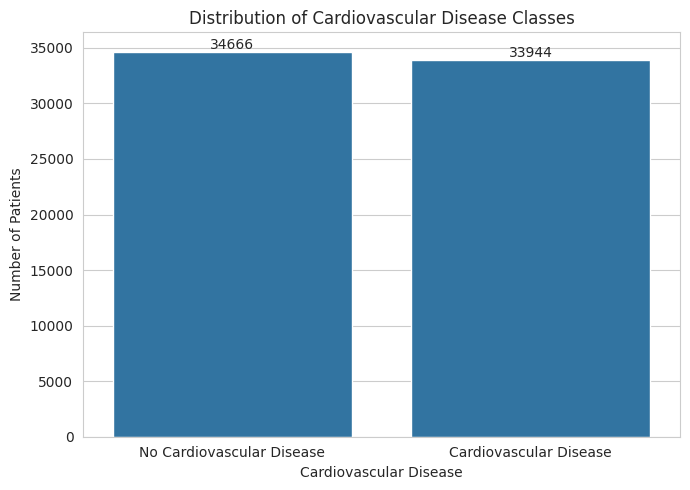

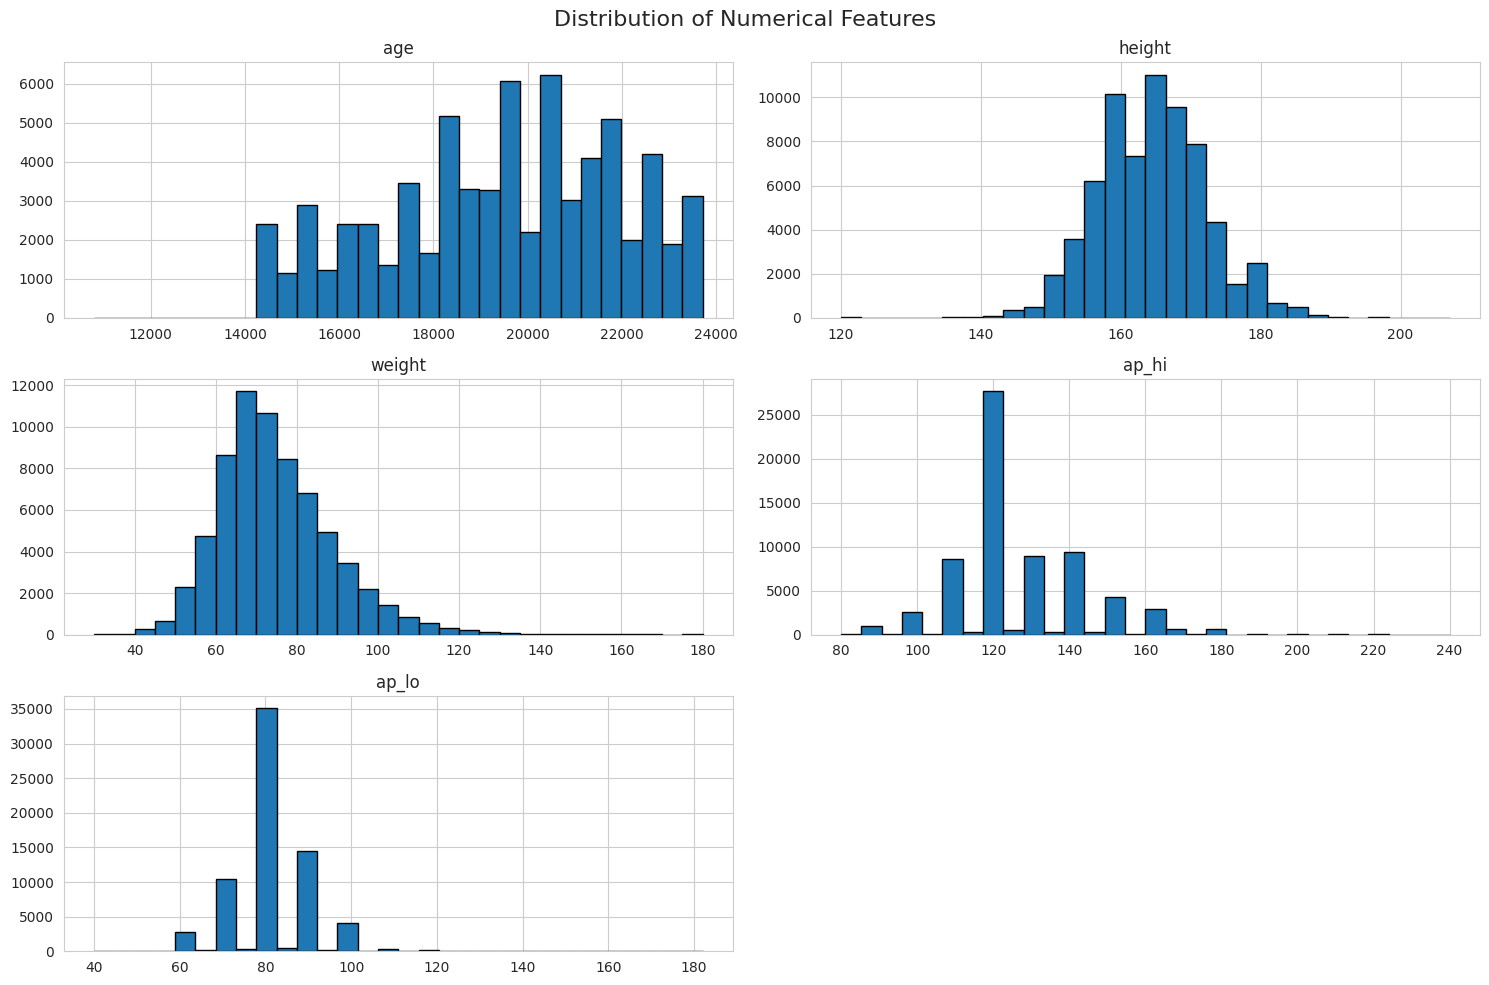

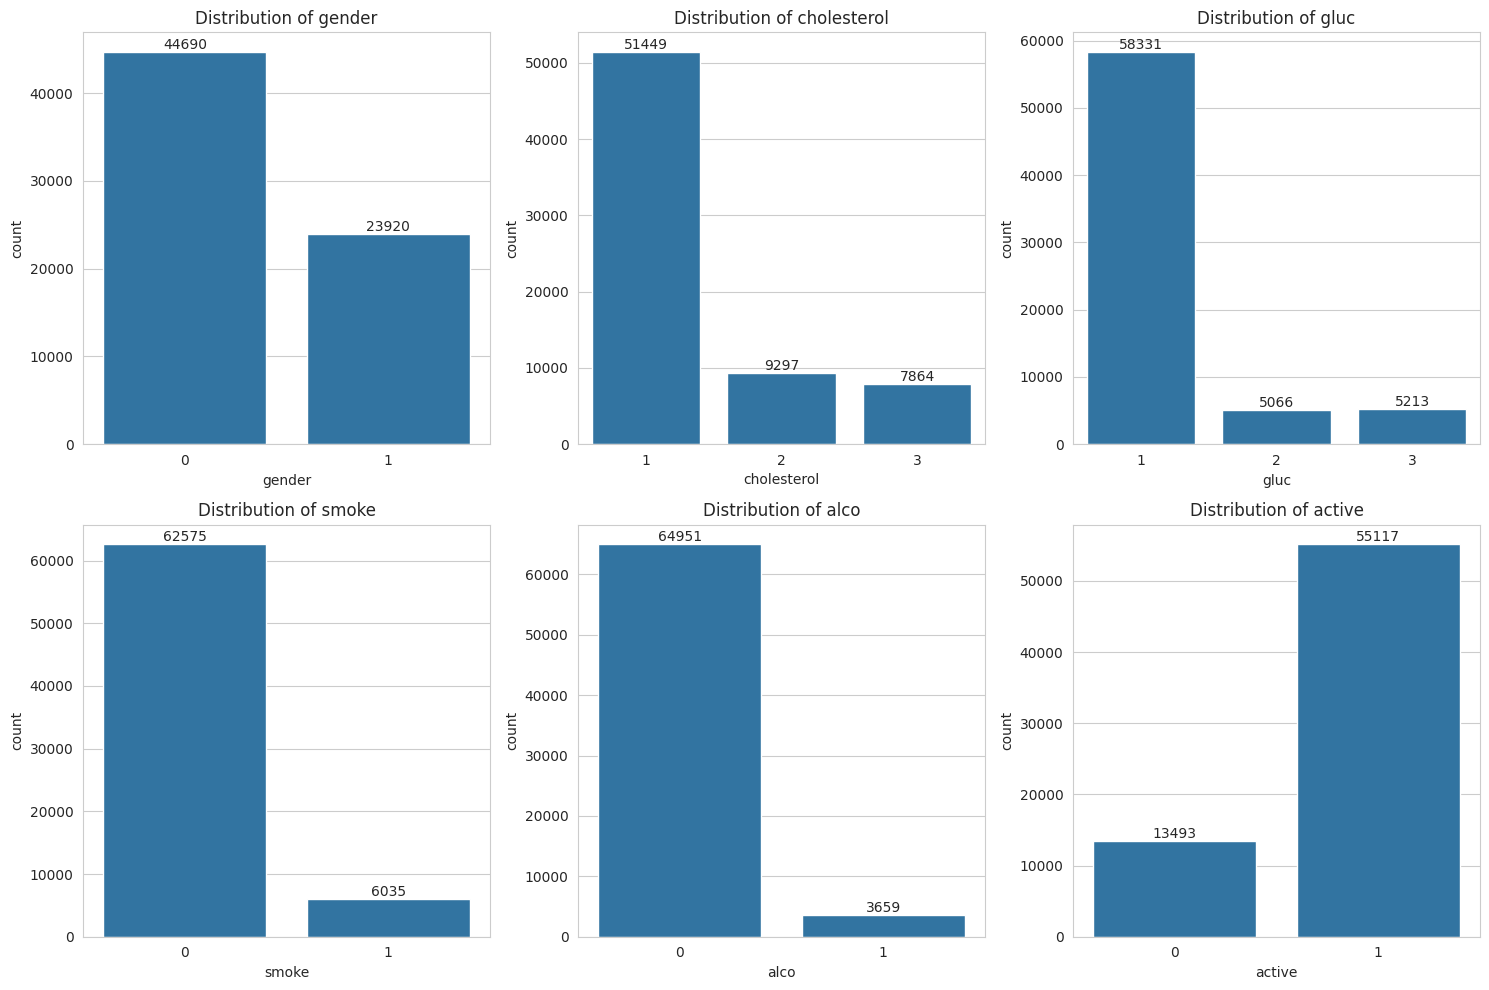


Correlation of Features with Cardiovascular Disease:
cardio         1.000000
ap_hi          0.428034
ap_lo          0.340080
age            0.239334
cholesterol    0.221396
weight         0.180191
gluc           0.089679
gender         0.007149
alco          -0.008595
height        -0.011880
smoke         -0.016339
active        -0.037734
Name: cardio, dtype: float64


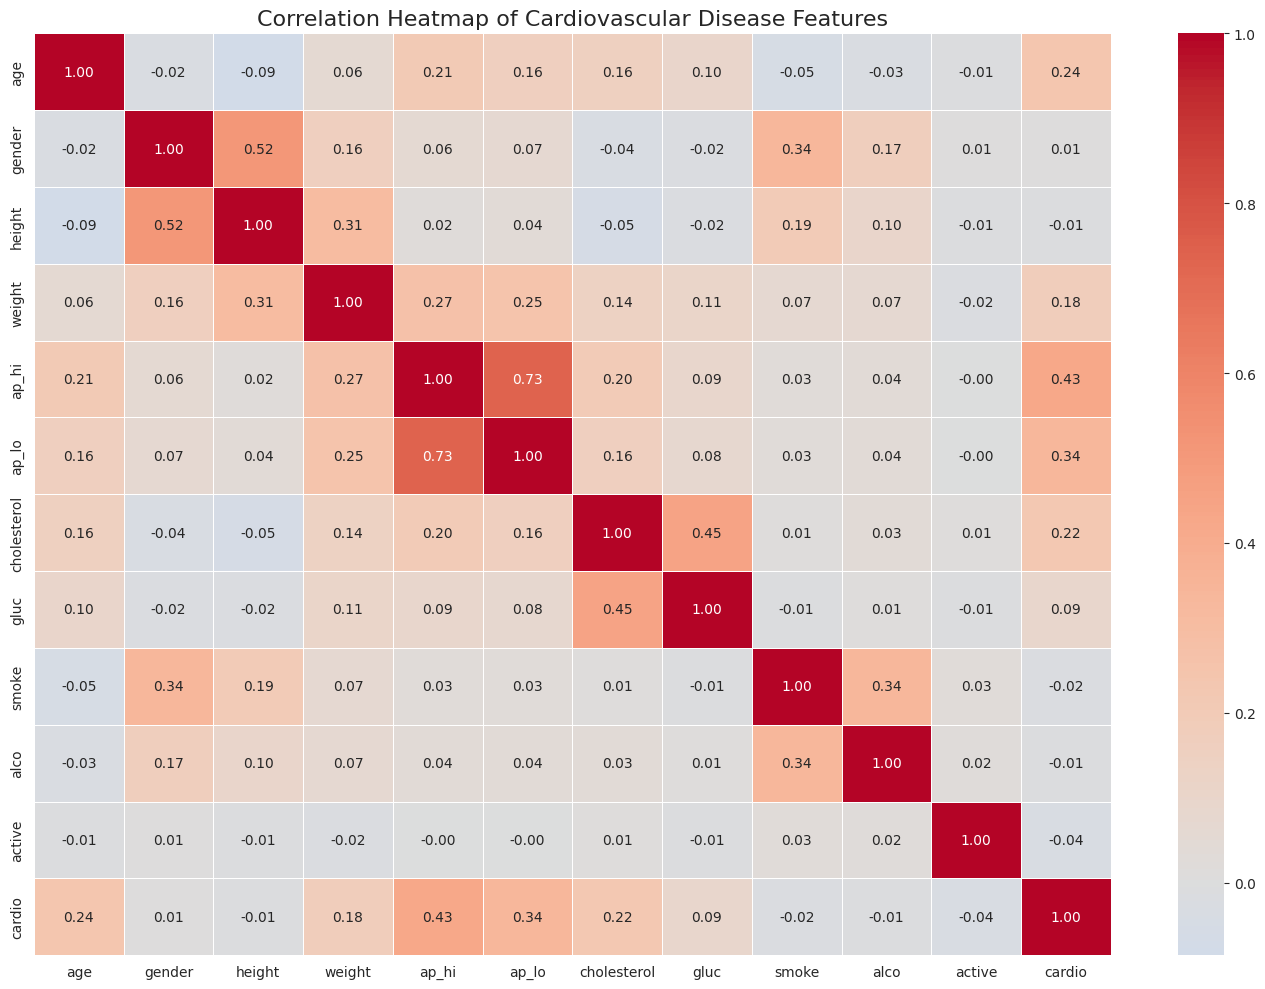

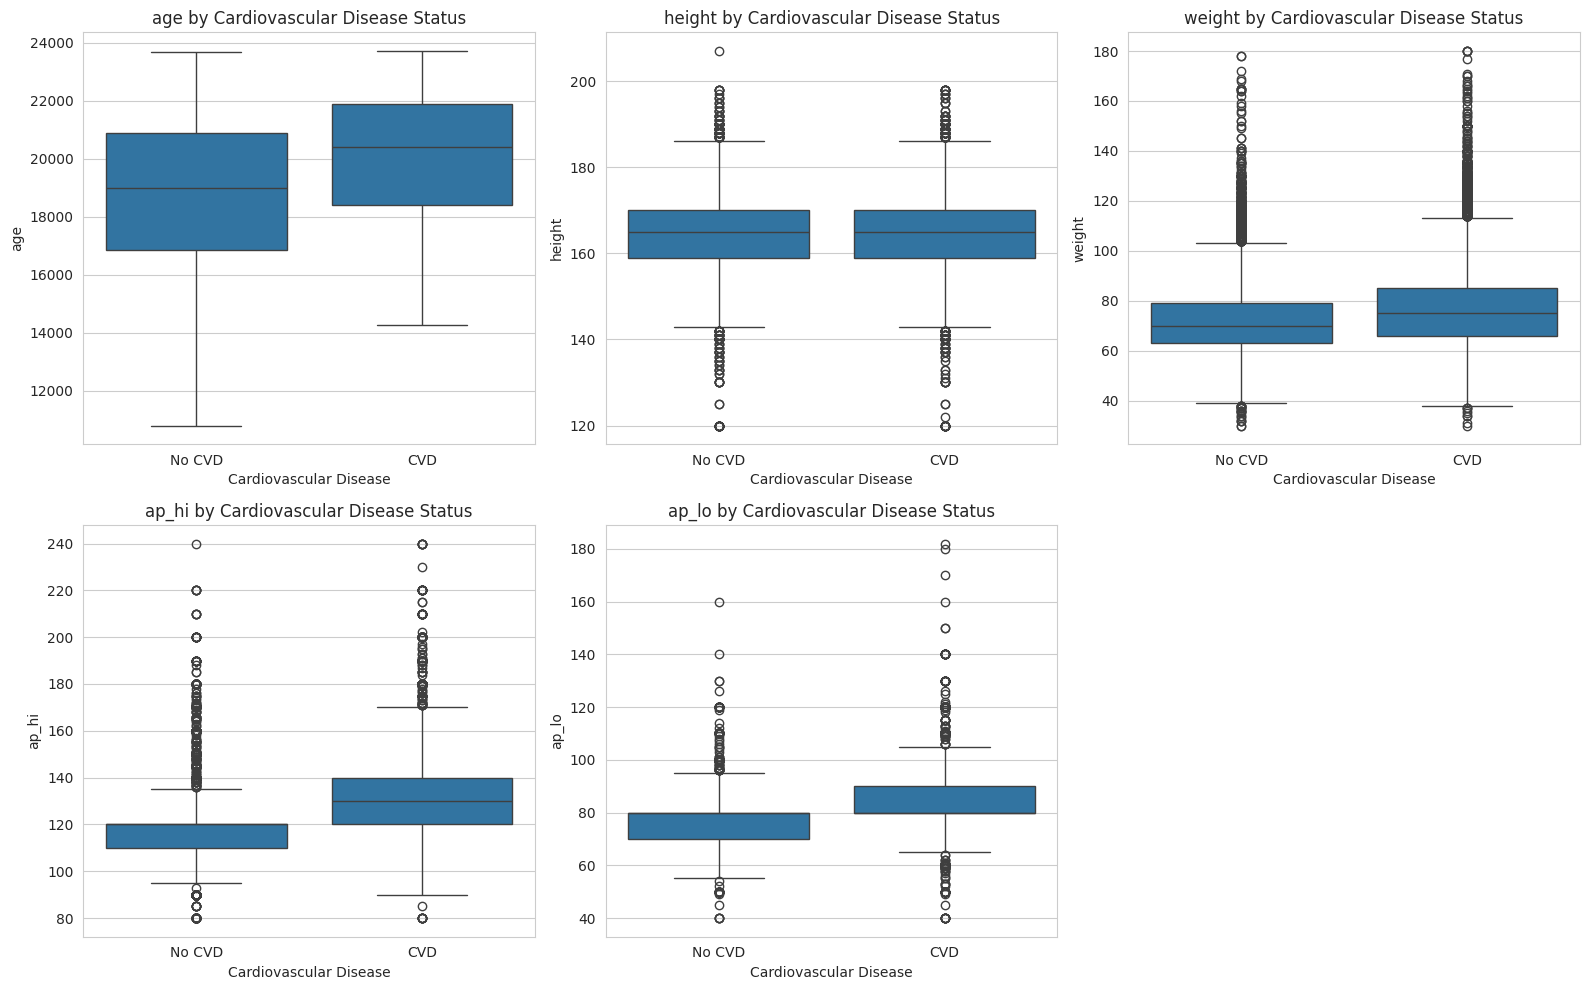

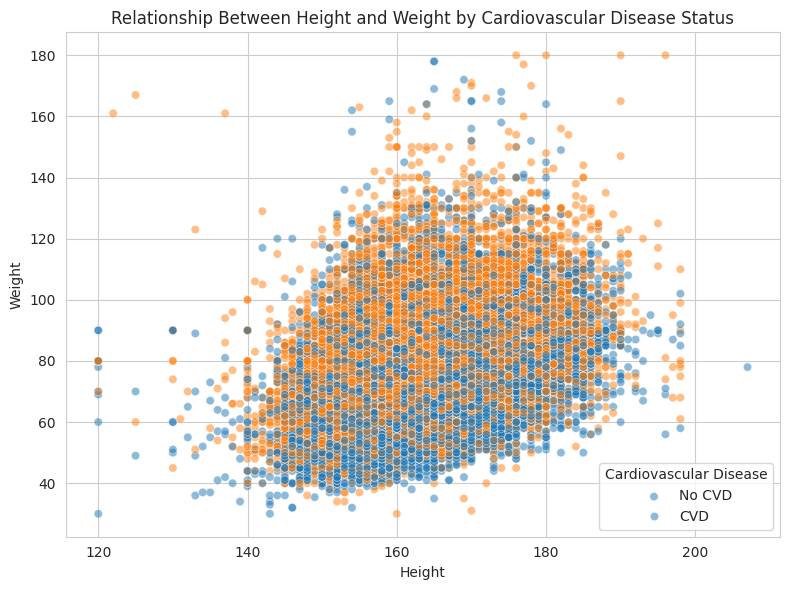

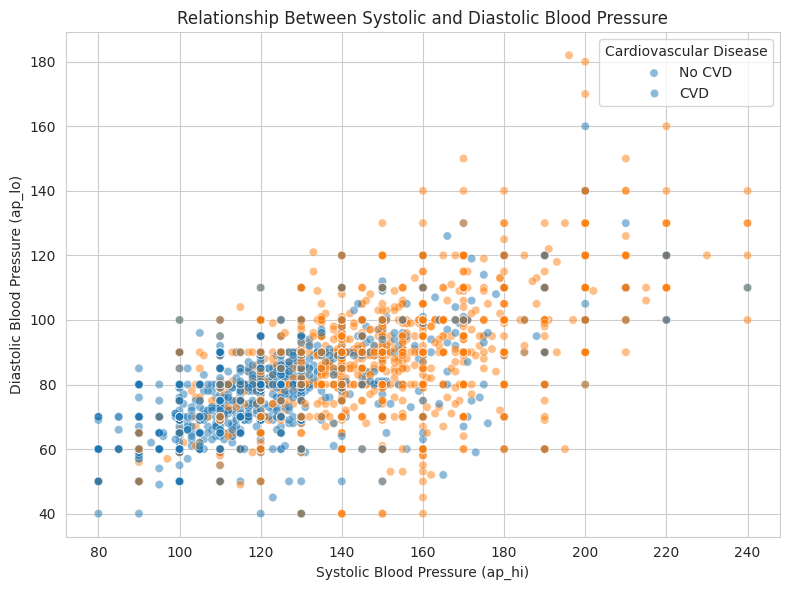

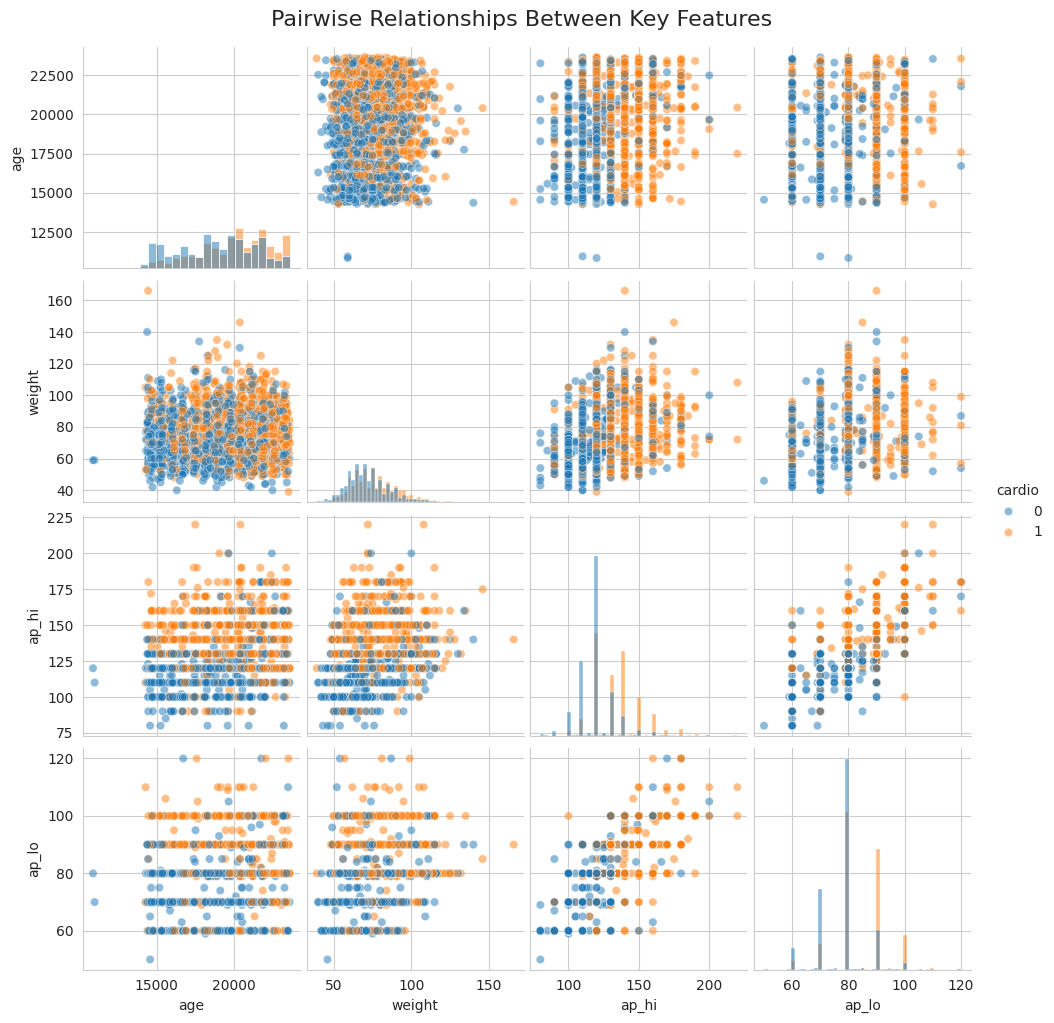

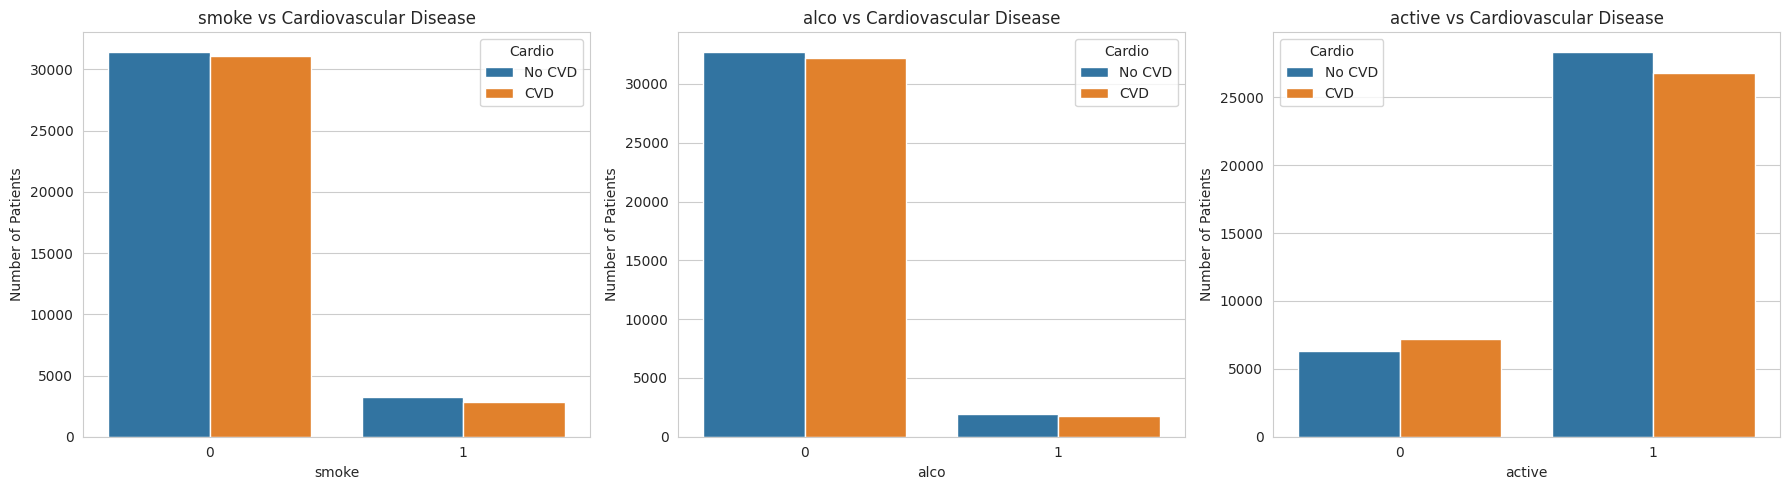

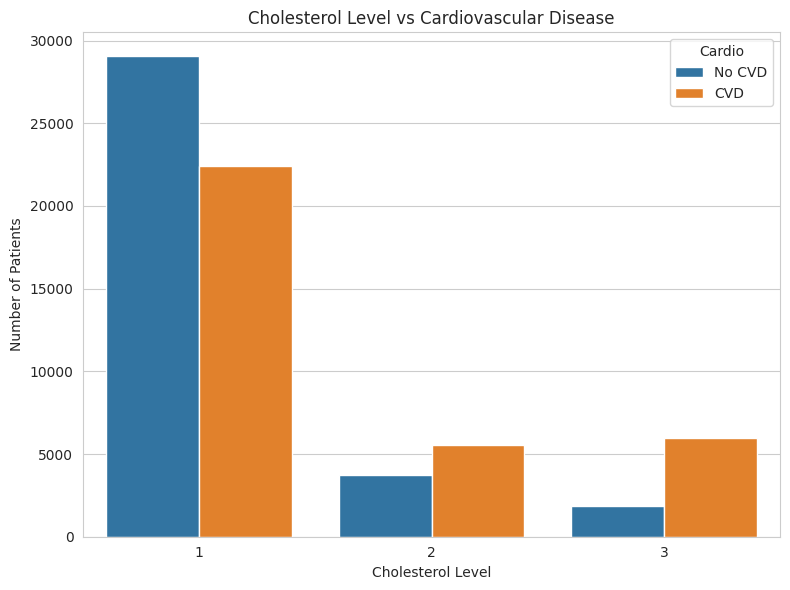

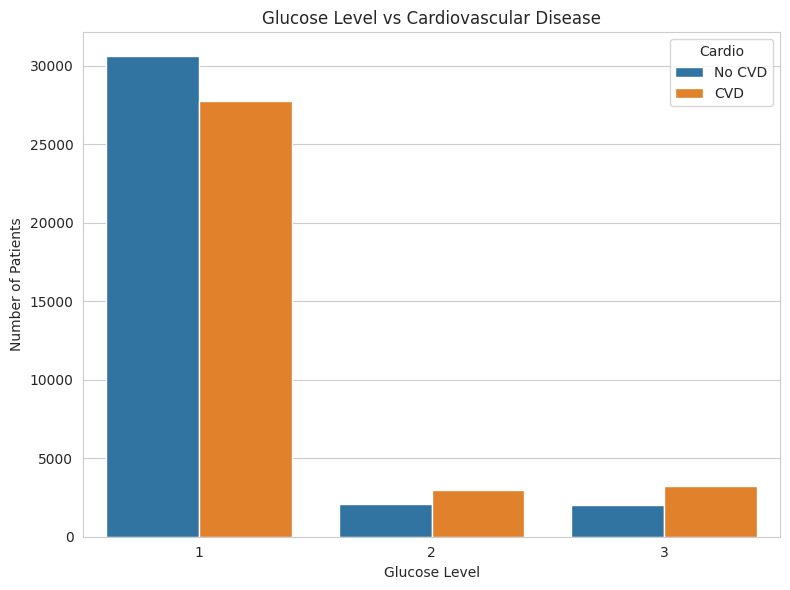

In [ ]:
# @title Exploratory Data Analysis (EDA)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

#Creating folder for EDA graphs in drive
EDA_GRAPHS_PATH = "/content/drive/MyDrive/Cardiovascular Disease/EDA Graphs"
os.makedirs(EDA_GRAPHS_PATH, exist_ok=True)
print(f"EDA graphs will be saved to: {EDA_GRAPHS_PATH}")

#Setting general plotting style
sns.set_style("whitegrid")

#Dataset overview
print("\nDataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nData Types and Non-Null Values:")
df.info()
print("\nDescriptive Statistics:")
display(df.describe())

#Class distribution
class_counts = df["cardio"].value_counts()
class_percentages = df["cardio"].value_counts(normalize=True) * 100
print("\nClass Counts:")
print(class_counts)
print("\nClass Percentages:")
print(class_percentages)

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="cardio")
plt.title("Distribution of Cardiovascular Disease Classes")
plt.xlabel("Cardiovascular Disease")
plt.ylabel("Number of Patients")
plt.xticks(ticks=[0, 1], labels=["No Cardiovascular Disease", "Cardiovascular Disease"])

#Displaying values on top of bars
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

#Numerical feature distribution
numerical_features = [
    "age",
    "height",
    "weight",
    "ap_hi",
    "ap_lo"
]

df[numerical_features].hist(figsize=(15, 10), bins=30, edgecolor="black")
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/numerical_feature_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


#Distribution of categorical variables
categorical_features = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    ax = sns.countplot(data=df, x=feature, ax=axes[i])
    axes[i].set_title(f"Distribution of {feature}")

    #Adding values above bars
    for container in ax.containers:
        ax.bar_label(container)

plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/categorical_variables.png", dpi=300, bbox_inches="tight")
plt.show()

#Correlation analysis
correlation_matrix = df.corr(numeric_only=True)

#Printing correlation with target variable
target_correlation = (correlation_matrix["cardio"].sort_values(ascending=False))
print("\nCorrelation of Features with Cardiovascular Disease:")
print(target_correlation)

#Heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Cardiovascular Disease Features", fontsize=16)
plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

#Boxplots
boxplot_features = [
    "age",
    "height",
    "weight",
    "ap_hi",
    "ap_lo"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(boxplot_features):
    sns.boxplot(data=df, x="cardio", y=feature, ax=axes[i])
    axes[i].set_title(f"{feature} by Cardiovascular Disease Status")
    axes[i].set_xlabel("Cardiovascular Disease")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["No CVD", "CVD"])

#Removing the unused subplot
fig.delaxes(axes[5])
plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

#Scatter plots
#Height vs Weight
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="height", y="weight", hue="cardio", alpha=0.5)
plt.title("Relationship Between Height and Weight by Cardiovascular Disease Status")
plt.xlabel("Height")
plt.ylabel("Weight")
plt.legend(title="Cardiovascular Disease", labels=["No CVD", "CVD"])
plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/height_weight_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

# Systolic vs Diastolic BP
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df, x="ap_hi", y="ap_lo", hue="cardio", alpha=0.5)
plt.title("Relationship Between Systolic and Diastolic Blood Pressure")
plt.xlabel("Systolic Blood Pressure (ap_hi)")
plt.ylabel("Diastolic Blood Pressure (ap_lo)")
plt.legend(title="Cardiovascular Disease", labels=["No CVD", "CVD"])
plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/systolic_diastolic_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

#Pairwise relationships
pairplot_features = [
    "age",
    "weight",
    "ap_hi",
    "ap_lo",
    "cardio"
]

sns.pairplot(df[pairplot_features].sample(n=min(3000, len(df)), random_state=SEED),
             hue="cardio", diag_kind="hist", plot_kws={"alpha": 0.5})
plt.suptitle("Pairwise Relationships Between Key Features", y=1.02, fontsize=16)
plt.savefig(f"{EDA_GRAPHS_PATH}/pairwise_relationships.png", dpi=300, bbox_inches="tight")
plt.show()

#Lifestyle factors vs CVD
lifestyle_features = [
    "smoke",
    "alco",
    "active"
]

fig, axes = plt.subplots( 1, 3, figsize=(18, 5))

for i, feature in enumerate(lifestyle_features):
    sns.countplot(data=df, x=feature, hue="cardio", ax=axes[i])
    axes[i].set_title(f"{feature} vs Cardiovascular Disease")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Number of Patients")
    axes[i].legend(title="Cardio", labels=["No CVD", "CVD"])

plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/lifestyle_factors.png", dpi=300, bbox_inches="tight")
plt.show()

#Cholesterol level vs CVD
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x="cholesterol", hue="cardio")
plt.title("Cholesterol Level vs Cardiovascular Disease")
plt.xlabel("Cholesterol Level")
plt.ylabel("Number of Patients")
plt.legend( title="Cardio", labels=["No CVD", "CVD"])
plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/cholesterol_level.png", dpi=300, bbox_inches="tight")
plt.show()

#Glucose level vs CVD
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x="gluc", hue="cardio")
plt.title("Glucose Level vs Cardiovascular Disease")
plt.xlabel("Glucose Level")
plt.ylabel("Number of Patients")
plt.legend(title="Cardio", labels=["No CVD", "CVD"])
plt.tight_layout()
plt.savefig(f"{EDA_GRAPHS_PATH}/glucose_level.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# @title Feature Engineering
import numpy as np
import pandas as pd

#Feature 1 - Age
#Converting age from days to years
df["age_years"] = df["age"] / 365.25

#Feature 2 - BMI
df["bmi"] = df["weight"] / ((df["height"] / 100) ** 2)

#Feature 3 - Pulse Pressure
df["pulse_pressure"] = df["ap_hi"] - df["ap_lo"]


#Feature 4 - Mean Arterial Pressure
df["mean_arterial_pressure"] = (df["ap_lo"] + (df["pulse_pressure"] / 3))

#Feature 5 - BMI Category
#0 - Underweight
#1 - Normal weight
#2 - Overweight
#3 - Obese

df["bmi_category"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, np.inf], labels=[0, 1, 2, 3], right=False).astype(int)

#Feature 6 - Age Category
# FEATURE 6: AGE CATEGORY
#0 - <40
#1 - 40–49
#2 - 50–59
#3 - 60–69
#4 - >70

df["age_category"] = pd.cut(df["age_years"], bins=[0, 40, 50, 60, 70, np.inf],
                            labels=[0, 1, 2, 3, 4], right=False).astype(int)

#Feature 7 - Hypertension Indicatorr
#0 - No hypertension
#1 - Hypertension

df["hypertension"] = ((df["ap_hi"] >= 140) | (df["ap_lo"] >= 90)).astype(int)

#Feature 8 - Lifestyle Risk Score
#Smoke - 1 indicates smoking
#Alco - 1 indicates alcohol consumption
#Active - 0 indicates physical inactivity
#Higher score = More lifestyle risk factors

df["lifestyle_risk_score"] = (df["smoke"] + df["alco"] + (1 - df["active"]))

#Feature engineering validation
#Listing of all newly created features
engineered_features = [
    "age_years",
    "bmi",
    "pulse_pressure",
    "mean_arterial_pressure",
    "bmi_category",
    "age_category",
    "hypertension",
    "lifestyle_risk_score"
]

print("\nNew engineered features:")
print(engineered_features)
print("\nDataset shape after feature engineering:")
print(df.shape)
print("\nFirst 5 rows of engineered features:")
display(df[engineered_features].head())
print("\nSummary statistics of engineered features:")
display(df[engineered_features].describe())

#Checking for missing values
print("\nMissing values in engineered features:")
print(df[engineered_features].isnull().sum())

#Checking for infinite values
numeric_engineered_features = df[engineered_features].select_dtypes(include=np.number)
print("\nInfinite values in engineered features:")
print(np.isinf(numeric_engineered_features).sum())

#Final check
print("\nFinal dataset columns:")
print(df.columns.tolist())
print("\nFinal dataset shape:")
print(df.shape)
# Save fully cleaned + engineered dataset (id dropped, engineered features included)
df.to_csv("/content/drive/MyDrive/Cardiovascular Disease/cardio_cleaned.csv", index=False)


New engineered features:
['age_years', 'bmi', 'pulse_pressure', 'mean_arterial_pressure', 'bmi_category', 'age_category', 'hypertension', 'lifestyle_risk_score']

Dataset shape after feature engineering:
(68610, 20)

First 5 rows of engineered features:


,age_years,bmi,pulse_pressure,mean_arterial_pressure,bmi_category,age_category,hypertension,lifestyle_risk_score
0,50.357290,21.967120,30,90.000000,1,2,0,0
1,55.381246,34.927679,50,106.666667,3,2,1,0
2,51.627652,23.507805,60,90.000000,1,2,0,1
3,48.249144,28.710479,50,116.666667,2,1,1,0
4,47.841205,23.011177,40,73.333333,1,1,0,1



Summary statistics of engineered features:


,age_years,bmi,pulse_pressure,mean_arterial_pressure,bmi_category,age_category,hypertension,lifestyle_risk_score
count,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000
mean,53.292478,27.456832,45.367702,96.433644,1.872264,1.845081,0.342909,0.337954
std,6.756780,5.253328,11.666787,11.048440,0.807857,0.741319,0.474685,0.567435
min,29.563313,10.726644,0.000000,53.333333,0.000000,0.000000,0.000000,0.000000
25%,48.344969,23.875115,40.000000,93.333333,1.000000,1.000000,0.000000,0.000000
50%,53.941136,26.346494,40.000000,93.333333,2.000000,2.000000,0.000000,0.000000
75%,58.384668,30.116213,50.000000,103.333333,3.000000,2.000000,1.000000,1.000000
max,64.922656,108.169847,140.000000,186.666667,3.000000,3.000000,1.000000,3.000000



Missing values in engineered features:
age_years                 0
bmi                       0
pulse_pressure            0
mean_arterial_pressure    0
bmi_category              0
age_category              0
hypertension              0
lifestyle_risk_score      0
dtype: int64

Infinite values in engineered features:
age_years                 0
bmi                       0
pulse_pressure            0
mean_arterial_pressure    0
bmi_category              0
age_category              0
hypertension              0
lifestyle_risk_score      0
dtype: int64

Final dataset columns:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'bmi', 'pulse_pressure', 'mean_arterial_pressure', 'bmi_category', 'age_category', 'hypertension', 'lifestyle_risk_score']

Final dataset shape:
(68610, 20)


In [ ]:
# @title Train-Test Split
from sklearn.model_selection import train_test_split

X = df.drop(columns=["cardio"])
y = df["cardio"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))
print("Test class balance:\n", y_test.value_counts(normalize=True))

Train shape: (54888, 19)
Test shape: (13722, 19)
Train class balance:
 cardio
0    0.505265
1    0.494735
Name: proportion, dtype: float64
Test class balance:
 cardio
0    0.505247
1    0.494753
Name: proportion, dtype: float64


In [ ]:
# @title Feature Selection: Multicollinearity Check
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

corr_matrix = X_train.corr()
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.85:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], round(r, 3)))

print("Highly correlated pairs (|r| > 0.85):")
for pair in sorted(high_corr_pairs, key=lambda x: -abs(x[2])):
    print(f"  {pair[0]:22s} <-> {pair[1]:22s}  r = {pair[2]}")

# Drop exact/near-exact algebraic duplicates before computing VIF,
# otherwise the design matrix is singular (confirmed: pulse_pressure and map
# are exact linear rearrangements of ap_hi/ap_lo; lifestyle_risk_score is an
# exact linear combination of smoke+alco+active; age_years is age/365.25)
X_vif_check = X_train.drop(columns=['age', 'pulse_pressure', 'mean_arterial_pressure', 'lifestyle_risk_score'])

# Add a constant column, older statsmodels versions require this to compute
# standard VIF correctly, otherwise the regression is forced through the
# origin and every VIF value comes out artificially inflated.
X_vif_check = X_vif_check.copy()
X_vif_check.insert(0, 'const', 1.0)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif_check.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif_check.values, i) for i in range(X_vif_check.shape[1])]
vif_data = vif_data[vif_data["feature"] != "const"]  # drop the constant row from what you display/report
print("\nVIF scores:")
print(vif_data.sort_values("VIF", ascending=False).to_string(index=False))

Highly correlated pairs (|r| > 0.85):
  age                    <-> age_years               r = 1.0
  ap_lo                  <-> mean_arterial_pressure  r = 0.94
  ap_hi                  <-> mean_arterial_pressure  r = 0.922
  age                    <-> age_category            r = 0.913
  age_years              <-> age_category            r = 0.913
  weight                 <-> bmi                     r = 0.861
  bmi                    <-> bmi_category            r = 0.861

VIF scores:
     feature       VIF
      weight 88.139651
         bmi 78.285831
      height 24.040112
   age_years  6.084968
age_category  5.998201
bmi_category  4.159990
       ap_hi  2.979218
hypertension  2.654614
       ap_lo  2.456445
      gender  1.500541
 cholesterol  1.334970
        gluc  1.268446
       smoke  1.244518
        alco  1.138508
      active  1.002146


In [ ]:
# @title Feature Selection: ANOVA, Mutual Information, Tree Importance
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.tree import DecisionTreeClassifier

# Candidate set after removing multicollinearity (age, weight, height, pulse_pressure,
# map, bmi_category, age_category, lifestyle_risk_score dropped as redundant)
candidate_cols = ['age_years','gender','ap_hi','ap_lo','cholesterol','gluc',
                   'smoke','alco','active','bmi','hypertension']
X_cand = X_train[candidate_cols]

f_scores, f_pvalues = f_classif(X_cand, y_train)
mi_scores = mutual_info_classif(X_cand, y_train, random_state=SEED)

dt_rank = DecisionTreeClassifier(max_depth=6, random_state=SEED)
dt_rank.fit(X_cand, y_train)

results = pd.DataFrame({
    'feature': candidate_cols,
    'ANOVA_F': f_scores, 'ANOVA_p': f_pvalues,
    'Mutual_Info': mi_scores, 'Tree_Importance': dt_rank.feature_importances_
})
results['avg_rank'] = results[['ANOVA_F','Mutual_Info','Tree_Importance']].rank(ascending=False).mean(axis=1)
print(results.sort_values('avg_rank').to_string(index=False))

# alco: p=0.274 (not significant), MI=0, tree importance=0 -> drop
selected_cols = ['age_years','gender','ap_hi','ap_lo','cholesterol','gluc',
                  'smoke','active','bmi','hypertension']

     feature      ANOVA_F       ANOVA_p  Mutual_Info  Tree_Importance  avg_rank
       ap_hi 12213.572872  0.000000e+00     0.118243         0.766406  1.000000
   age_years  3364.762870  0.000000e+00     0.033097         0.124839  3.333333
hypertension 10976.852787  0.000000e+00     0.088906         0.003183  3.333333
       ap_lo  7045.352470  0.000000e+00     0.071120         0.001221  4.333333
 cholesterol  2794.437000  0.000000e+00     0.027176         0.072819  4.666667
         bmi  2028.345920  0.000000e+00     0.028031         0.022014  5.000000
        gluc   469.351774 1.207754e-103     0.008108         0.007014  6.333333
      active    82.596209  1.039010e-19     0.005623         0.001207  8.000000
       smoke    13.328643  2.616252e-04     0.001091         0.000914  9.333333
      gender     4.741929  2.944030e-02     0.004452         0.000384  9.666667
        alco     1.195549  2.742180e-01     0.000000         0.000000 11.000000


In [ ]:
# @title Feature Selection: Compare Feature Sets (Preliminary Result)
from sklearn.model_selection import StratifiedKFold, cross_validate

original_cols = ['age_years','gender','height','weight','ap_hi','ap_lo',
                  'cholesterol','gluc','smoke','alco','active']
engineered_cols = list(X_train.columns)

feature_sets = {'Original': original_cols, 'Full Engineered': engineered_cols, 'Selected': selected_cols}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for name, cols in feature_sets.items():
    clf = DecisionTreeClassifier(max_depth=6, random_state=SEED)
    scores = cross_validate(clf, X_train[cols], y_train, cv=cv, scoring=['accuracy','f1'])
    print(f"{name:<18} n={len(cols):<3} "
          f"Acc={scores['test_accuracy'].mean():.4f}±{scores['test_accuracy'].std():.4f}  "
          f"F1={scores['test_f1'].mean():.4f}±{scores['test_f1'].std():.4f}")

Original           n=11  Acc=0.7274±0.0053  F1=0.7096±0.0091
Full Engineered    n=19  Acc=0.7279±0.0049  F1=0.7117±0.0068
Selected           n=10  Acc=0.7278±0.0054  F1=0.7142±0.0071


In [ ]:
# @title Finalize Feature Set for Modeling
X_train = X_train[selected_cols]
X_test = X_test[selected_cols]
print("Modeling feature set:", list(X_train.columns))
print("X_train shape:", X_train.shape, " X_test shape:", X_test.shape)

Modeling feature set: ['age_years', 'gender', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'active', 'bmi', 'hypertension']
X_train shape: (54888, 10)  X_test shape: (13722, 10)


In [ ]:
# @title Model Graphs Setup
import os
MODEL_GRAPHS_PATH = "/content/drive/MyDrive/Cardiovascular Disease/Model Graphs"
os.makedirs(MODEL_GRAPHS_PATH, exist_ok=True)
print(f"Model graphs will be saved to: {MODEL_GRAPHS_PATH}")

Model graphs will be saved to: /content/drive/MyDrive/Cardiovascular Disease/Model Graphs


In [ ]:
# @title Checkpoint Saving/Loading
import joblib
import os

CHECKPOINT_PATH = "/content/drive/MyDrive/Cardiovascular Disease/Checkpoints"
os.makedirs(CHECKPOINT_PATH, exist_ok=True)

def save_checkpoint(obj, name):
  joblib.dump(obj, f"{CHECKPOINT_PATH}/{name}.pkl")
  print(f"Saved {name}.pkl")

def load_checkpoint(name):
  path = f"{CHECKPOINT_PATH}/{name}.pkl"
  if os.path.exists(path):
    print(f"Loaded {name}.pkl (skipped refitting)")
    return joblib.load(path)
  return None

Max Depth   CV Accuracy (mean ± std)    CV F1 (mean ± std)
5           0.7266 ± 0.0046             0.7035 ± 0.0101
10          0.7239 ± 0.0052             0.7084 ± 0.0060
15          0.7057 ± 0.0048             0.6895 ± 0.0060
20          0.6817 ± 0.0052             0.6666 ± 0.0075

Best config by mean CV accuracy: max_depth=5


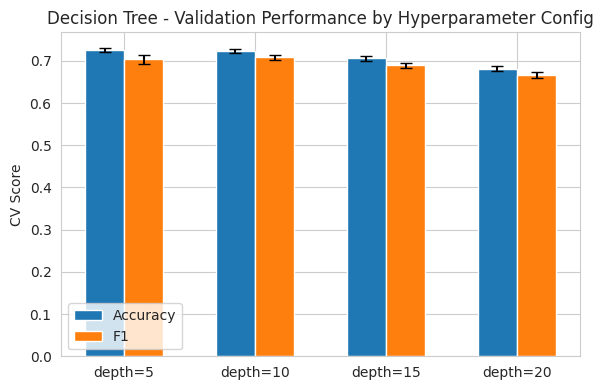

In [ ]:
# @title Model 1: Decision Tree - Hyperparameter Search (5-fold CV)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = [5, 10, 15, 20]

dt_search_results = []
print(f"{'Max Depth':<12}{'CV Accuracy (mean ± std)':<28}{'CV F1 (mean ± std)'}")
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    scores = cross_validate(clf, X_train, y_train, cv=cv, scoring=['accuracy','f1'])
    acc_mean, acc_std = scores['test_accuracy'].mean(), scores['test_accuracy'].std()
    f1_mean, f1_std = scores['test_f1'].mean(), scores['test_f1'].std()
    dt_search_results.append({'config': f'depth={d}', 'depth': d,
                               'acc_mean': acc_mean, 'acc_std': acc_std,
                               'f1_mean': f1_mean, 'f1_std': f1_std})
    acc_str = f"{acc_mean:.4f} ± {acc_std:.4f}"
    f1_str = f"{f1_mean:.4f} ± {f1_std:.4f}"
    print(f"{d:<12}{acc_str:<28}{f1_str}")

dt_search_df = pd.DataFrame(dt_search_results)
best_depth = dt_search_df.loc[dt_search_df['acc_mean'].idxmax(), 'depth']
print(f"\nBest config by mean CV accuracy: max_depth={best_depth}")

# Validation performance plot (required by the brief)
fig, ax = plt.subplots(figsize=(6,4))
x = range(len(dt_search_df))
ax.bar([i-0.15 for i in x], dt_search_df['acc_mean'], width=0.3, yerr=dt_search_df['acc_std'], capsize=4, label='Accuracy')
ax.bar([i+0.15 for i in x], dt_search_df['f1_mean'], width=0.3, yerr=dt_search_df['f1_std'], capsize=4, label='F1')
ax.set_xticks(list(x))
ax.set_xticklabels(dt_search_df['config'])
ax.set_ylabel('CV Score')
ax.set_title('Decision Tree - Validation Performance by Hyperparameter Config')
ax.legend()
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/dt_validation_performance.png", dpi=300, bbox_inches="tight")
plt.show()

Loaded svm_search_df.pkl (skipped refitting)
Kernel    CV Accuracy (mean ± std)    CV F1 (mean ± std)
linear    0.6953 ± 0.0023             0.6359 ± 0.0030
poly      0.7192 ± 0.0033             0.6823 ± 0.0040
rbf       0.7273 ± 0.0049             0.7004 ± 0.0056
sigmoid   0.6440 ± 0.0091             0.6398 ± 0.0083

Best config by mean CV accuracy: kernel=rbf


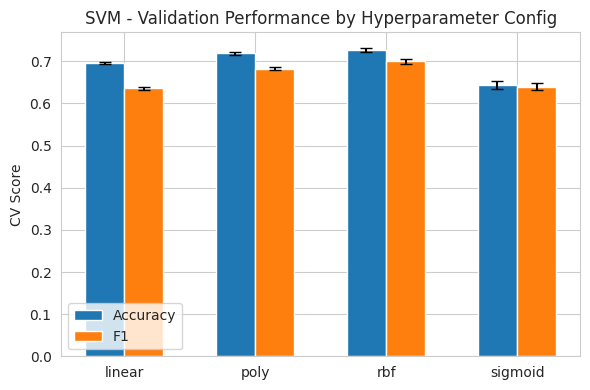

In [ ]:
# @title Model 2: SVM - Hyperparameter Search (5-fold CV)
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svm_search_df = load_checkpoint("svm_search_df")
if svm_search_df is None:
    kernels = ['linear', 'poly', 'rbf', 'sigmoid']
    svm_search_results = []
    print(f"{'Kernel':<10}{'CV Accuracy (mean ± std)':<28}{'CV F1 (mean ± std)'}")
    for k in kernels:
        pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel=k, random_state=SEED))])
        scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy','f1'])
        acc_mean, acc_std = scores['test_accuracy'].mean(), scores['test_accuracy'].std()
        f1_mean, f1_std = scores['test_f1'].mean(), scores['test_f1'].std()
        svm_search_results.append({'config': k, 'kernel': k,
                                    'acc_mean': acc_mean, 'acc_std': acc_std,
                                    'f1_mean': f1_mean, 'f1_std': f1_std})
        acc_str = f"{acc_mean:.4f} ± {acc_std:.4f}"
        f1_str = f"{f1_mean:.4f} ± {f1_std:.4f}"
        print(f"{k:<10}{acc_str:<28}{f1_str}")
    svm_search_df = pd.DataFrame(svm_search_results)
    save_checkpoint(svm_search_df, "svm_search_df")
else:
    print(f"{'Kernel':<10}{'CV Accuracy (mean ± std)':<28}{'CV F1 (mean ± std)'}")
    for _, row in svm_search_df.iterrows():
      acc_str = f"{row['acc_mean']:.4f} ± {row['acc_std']:.4f}"
      f1_str = f"{row['f1_mean']:.4f} ± {row['f1_std']:.4f}"
      print(f"{row['kernel']:<10}{acc_str:<28}{f1_str}")

best_kernel = svm_search_df.loc[svm_search_df['acc_mean'].idxmax(), 'kernel']
print(f"\nBest config by mean CV accuracy: kernel={best_kernel}")

fig, ax = plt.subplots(figsize=(6,4))
x = range(len(svm_search_df))
ax.bar([i-0.15 for i in x], svm_search_df['acc_mean'], width=0.3, yerr=svm_search_df['acc_std'], capsize=4, label='Accuracy')
ax.bar([i+0.15 for i in x], svm_search_df['f1_mean'], width=0.3, yerr=svm_search_df['f1_std'], capsize=4, label='F1')
ax.set_xticks(list(x))
ax.set_xticklabels(svm_search_df['config'])
ax.set_ylabel('CV Score')
ax.set_title('SVM - Validation Performance by Hyperparameter Config')
ax.legend()
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/svm_validation_performance.png", dpi=300, bbox_inches="tight")
plt.show()


Decision Tree (max_depth=5) (test set, evaluated once)

Accuracy:    0.7371
Precision:   0.7679
Recall:      0.6717
Specificity: 0.8012
F1-score:    0.7166
ROC-AUC:     0.7962
MCC:         0.4772



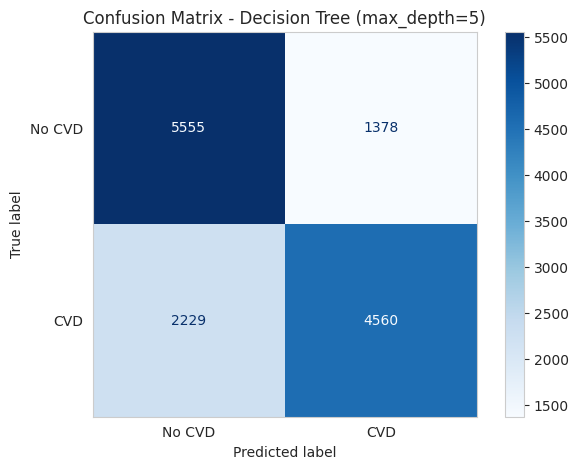

Loaded svm_final.pkl (skipped refitting)

SVM (kernel=rbf) (test set, evaluated once)

Accuracy:    0.7366
Precision:   0.7737
Recall:      0.6608
Specificity: 0.8108
F1-score:    0.7128
ROC-AUC:     0.7904
MCC:         0.4773



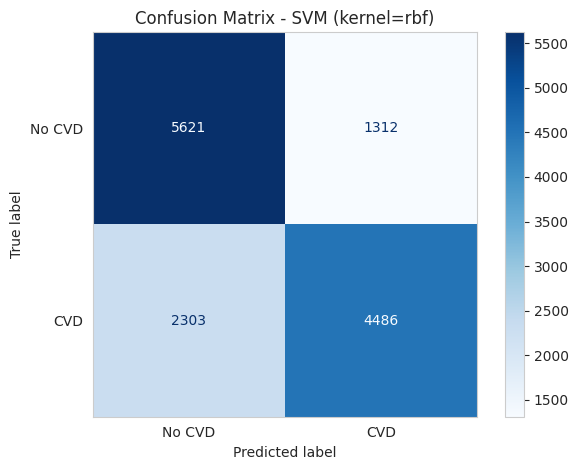

Cohen's Kappa (Decision Tree): 0.4735
Cohen's Kappa (SVM):           0.4723


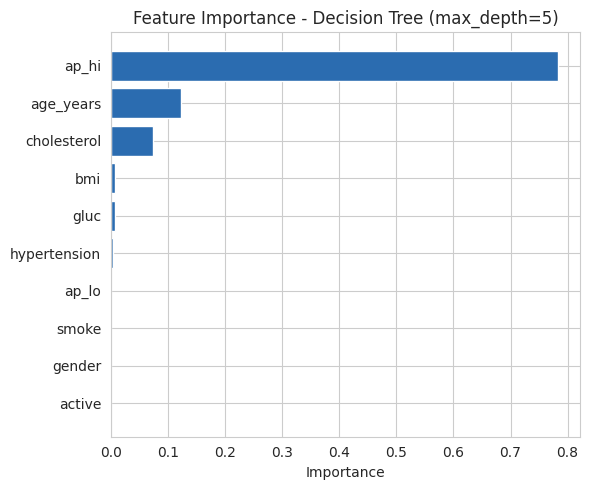

In [ ]:
# @title Final Models: Retrain on Full Train, Evaluate Once on Test
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, matthews_corrcoef, confusion_matrix,
                              ConfusionMatrixDisplay)
from sklearn.metrics import cohen_kappa_score

def evaluate(name, y_true, y_pred, y_score, filename):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp)

    print(f"\n{name} (test set, evaluated once)\n")
    print(f"Accuracy:    {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision:   {precision_score(y_true, y_pred):.4f}")
    print(f"Recall:      {recall_score(y_true, y_pred):.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"F1-score:    {f1_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC:     {roc_auc_score(y_true, y_score):.4f}")
    print(f"MCC:         {matthews_corrcoef(y_true, y_pred):.4f}\n")

    disp = ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        display_labels=["No CVD", "CVD"],
        cmap="Blues",
        values_format="d"
    )
    disp.ax_.grid(False)
    disp.ax_.set_title(f"Confusion Matrix - {name}")
    disp.figure_.tight_layout()
    disp.figure_.savefig(f"{MODEL_GRAPHS_PATH}/{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()

# Decision Tree - best config from CV above
dt_final = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)
dt_final.fit(X_train, y_train)
dt_pred = dt_final.predict(X_test)
dt_proba = dt_final.predict_proba(X_test)[:, 1]
evaluate(f"Decision Tree (max_depth={best_depth})", y_test, dt_pred, dt_proba, "confusion_matrix_decision_tree")

# SVM - best config from CV above. probability=False (much faster);
# use decision_function for ROC-AUC instead of predict_proba.
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
svm_final = load_checkpoint("svm_final")
if svm_final is None:
  svm_final = SVC(kernel=best_kernel, random_state=SEED)
  svm_final.fit(X_train_s, y_train)
  save_checkpoint(svm_final, "svm_final")

svm_pred = svm_final.predict(X_test_s)
svm_score = svm_final.decision_function(X_test_s)
evaluate(f"SVM (kernel={best_kernel})", y_test, svm_pred, svm_score, "confusion_matrix_svm")

print(f"Cohen's Kappa (Decision Tree): {cohen_kappa_score(y_test, dt_pred):.4f}")
print(f"Cohen's Kappa (SVM):           {cohen_kappa_score(y_test, svm_pred):.4f}")

# Feature Importance - Decision Tree (from the real tuned final model, required plot)
importance_df = pd.DataFrame({
    'feature': selected_cols,
    'importance': dt_final.feature_importances_
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(6,5))
ax.barh(importance_df['feature'], importance_df['importance'], color='#2b6cb0')
ax.invert_yaxis()
ax.set_xlabel('Importance')
ax.set_title(f'Feature Importance - Decision Tree (max_depth={best_depth})')
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/feature_importance_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()

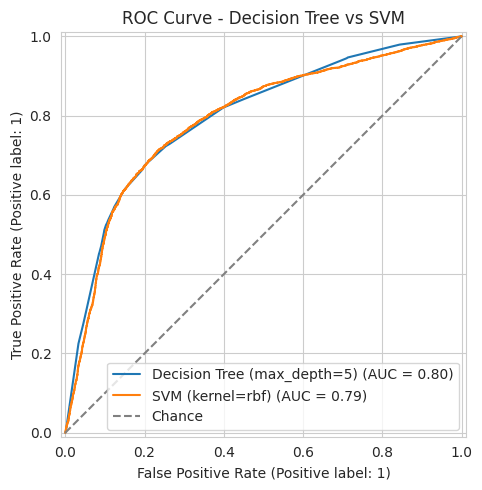

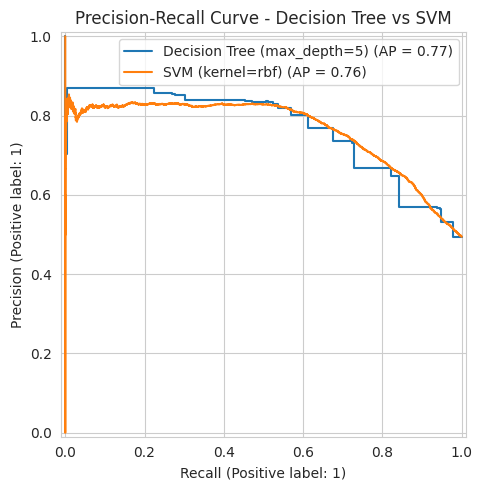

In [ ]:
# @title ROC Curve and Precision-Recall Curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# ROC Curve comparison
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, dt_proba, name=f"Decision Tree (max_depth={best_depth})", ax=ax)
RocCurveDisplay.from_predictions(y_test, svm_score, name=f"SVM (kernel={best_kernel})", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_title("ROC Curve - Decision Tree vs SVM")
ax.legend()
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/roc_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print()

# Precision-Recall Curve comparison
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, dt_proba, name=f"Decision Tree (max_depth={best_depth})", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, svm_score, name=f"SVM (kernel={best_kernel})", ax=ax)
ax.set_title("Precision-Recall Curve - Decision Tree vs SVM")
ax.legend()
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/precision_recall_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

Loaded learning_curve_data.pkl (skipped refitting)
Learning curve already generated, loading saved image


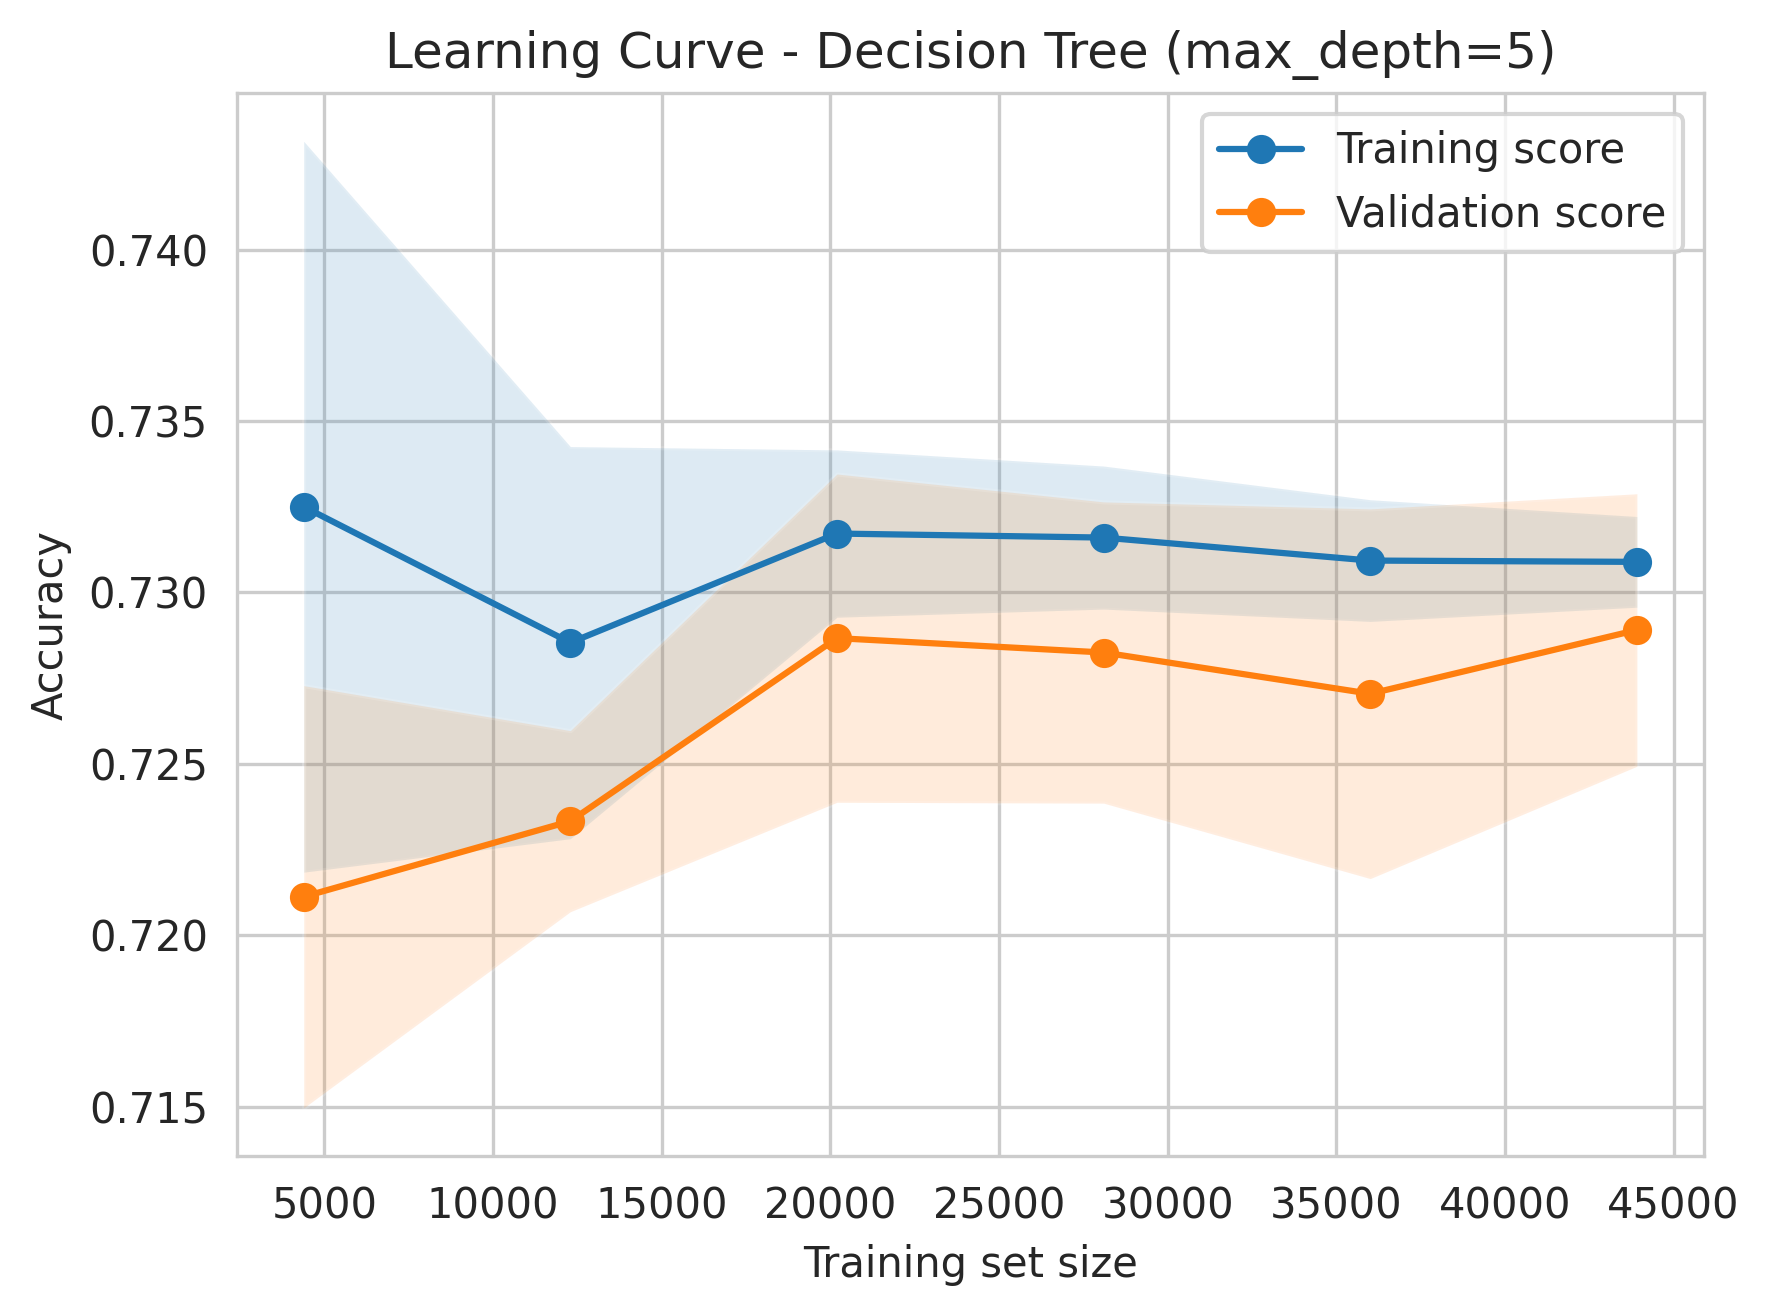

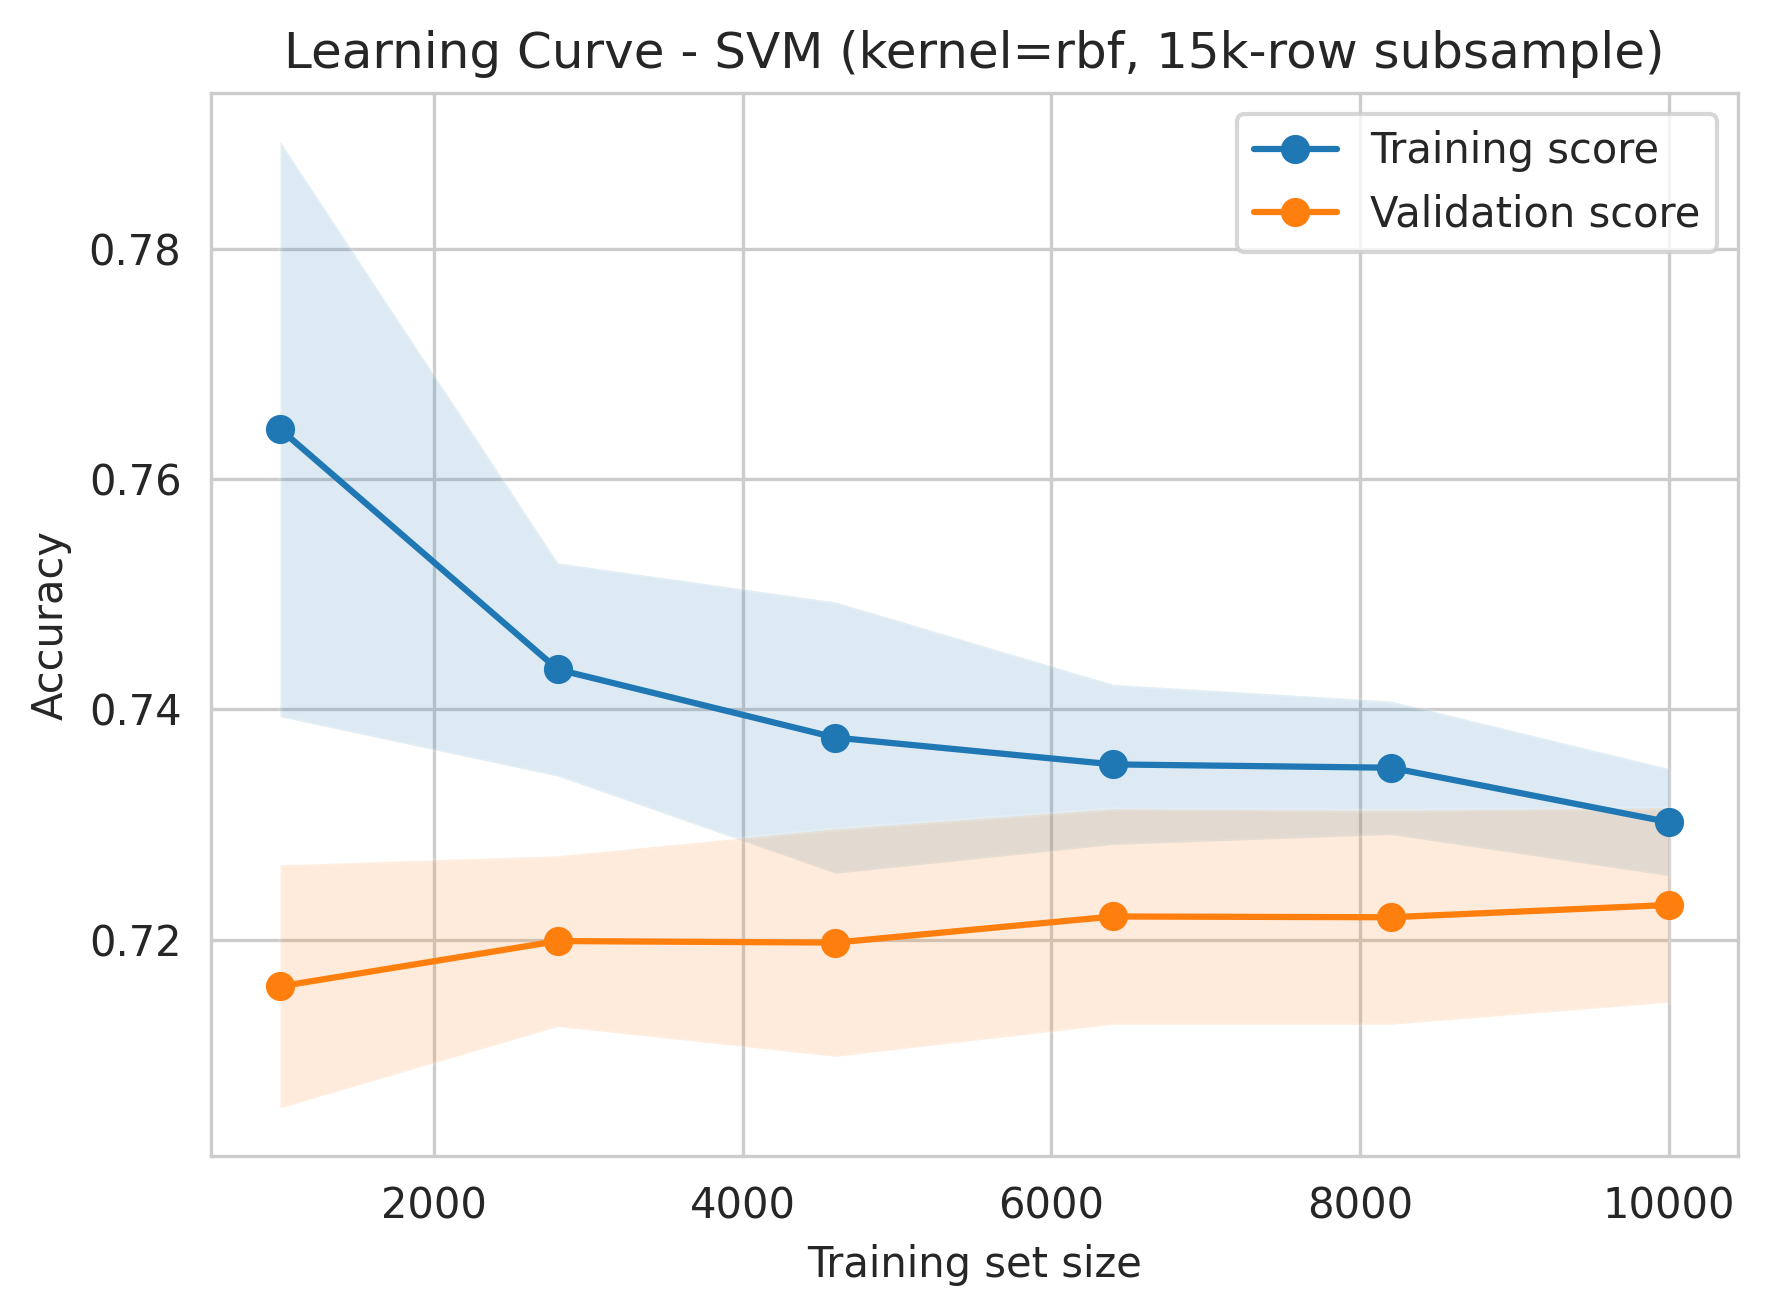

In [ ]:
# @title Learning Curves
from sklearn.model_selection import learning_curve, train_test_split
from IPython.display import Image, display
import numpy as np

def plot_learning_curve(estimator, X, y, title, filename, cv=5, train_sizes=np.linspace(0.1, 1.0, 6)):
    sizes, train_scores, val_scores = learning_curve(
        estimator, X, y, cv=cv, scoring='accuracy',
        train_sizes=train_sizes, random_state=SEED, n_jobs=-1
    )
    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

    fig, ax = plt.subplots(figsize=(6,4.5))
    ax.plot(sizes, train_mean, 'o-', label='Training score')
    ax.fill_between(sizes, train_mean-train_std, train_mean+train_std, alpha=0.15)
    ax.plot(sizes, val_mean, 'o-', label='Validation score')
    ax.fill_between(sizes, val_mean-val_std, val_mean+val_std, alpha=0.15)
    ax.set_xlabel('Training set size')
    ax.set_ylabel('Accuracy')
    ax.set_title(title)
    ax.legend(loc='best')
    fig.tight_layout()
    fig.savefig(f"{MODEL_GRAPHS_PATH}/{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("\n")

cached_lc = load_checkpoint("learning_curve_data")
if cached_lc is None:
  # Decision Tree - full training set, this one's fast
  plot_learning_curve(
      DecisionTreeClassifier(max_depth=best_depth, random_state=SEED),
      X_train, y_train,
      f"Learning Curve - Decision Tree (max_depth={best_depth})",
      "learning_curve_decision_tree"
  )

  # SVM - run on a stratified 15,000-row subsample. An SVM learning curve refits
  # the model at every training-set size, so at the full ~55,000 rows this could
  # take well over an hour. 15,000 rows keeps it to a few minutes while still
  # showing the real bias/variance trend. State this subsampling choice in your
  # report if you include this figure.
  X_lc, _, y_lc, _ = train_test_split(X_train, y_train, train_size=15000, stratify=y_train, random_state=SEED)
  plot_learning_curve(
      Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel=best_kernel, random_state=SEED))]),
      X_lc, y_lc,
      f"Learning Curve - SVM (kernel={best_kernel}, 15k-row subsample)",
      "learning_curve_svm",
      cv=3
  )
  save_checkpoint(True, "learning_curve_data")
else:
  print("Learning curve already generated, loading saved image")
  display(Image(f"{MODEL_GRAPHS_PATH}/learning_curve_decision_tree.png"))
  display(Image(f"{MODEL_GRAPHS_PATH}/learning_curve_svm.png"))

Loaded ensemble_search_df.pkl (skipped refitting)
Config                          CV Accuracy (mean ± std)    CV F1 (mean ± std)
Soft Voting (equal)             0.7303 ± 0.0055             0.7056 ± 0.0073
Soft Voting (DT-weighted)       0.7300 ± 0.0049             0.7051 ± 0.0076
Soft Voting (SVM-weighted)      0.7295 ± 0.0054             0.7052 ± 0.0063
Stacking (logistic meta-learner)0.7299 ± 0.0042             0.7071 ± 0.0076

Best config by mean CV accuracy: Soft Voting (equal)


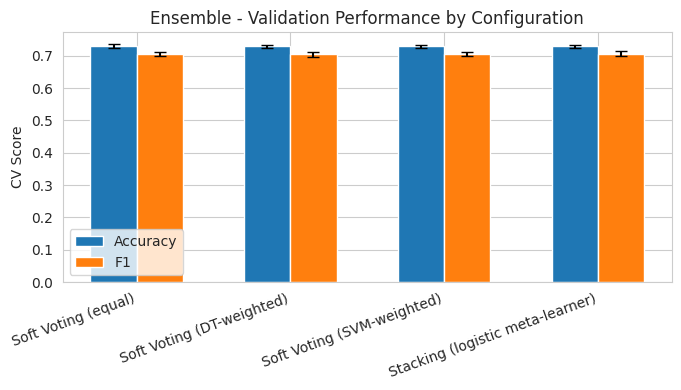

Loaded ensemble_cv_df.pkl (skipped refitting)
Model                           CV Accuracy (mean ± std)    CV F1 (mean ± std)
Decision Tree                   0.7266 ± 0.0046             0.7035 ± 0.0101
SVM                             0.7273 ± 0.0049             0.7004 ± 0.0056
Ensemble (Soft Voting (equal))  0.7303 ± 0.0055             0.7056 ± 0.0073
Loaded ensemble_fitted.pkl (skipped refitting)

Ensemble (Soft Voting (equal)) (test set, evaluated once)

Accuracy:    0.7389
Precision:   0.7747
Recall:      0.6659
Specificity: 0.8103
F1-score:    0.7162
ROC-AUC:     0.8015
MCC:         0.4816



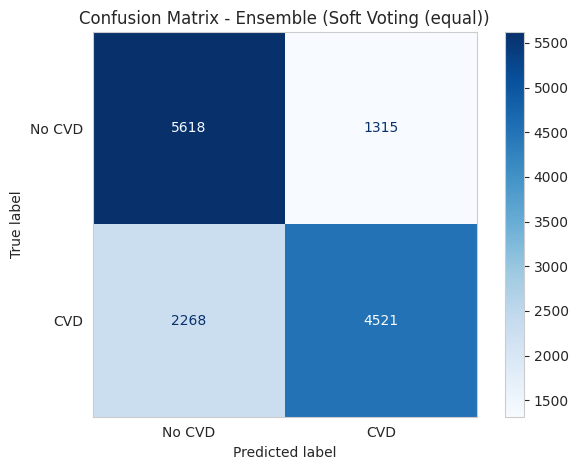

Cohen's Kappa (Ensemble): 0.4770


In [ ]:
# @title Model 3: Ensemble Configuration Search (5-fold CV)
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# probability=True needed for soft voting (SVM must output probabilities, not just decision scores)
dt_estimator = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)
svm_estimator = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel=best_kernel, probability=True, random_state=SEED))
])

# ensemble = VotingClassifier(
#     estimators=[('dt', dt_estimator), ('svm', svm_estimator)],
#     voting='soft',
#     n_jobs=-1
# )

ensemble_configs = {
    "Soft Voting (equal)": VotingClassifier(
        estimators=[('dt', dt_estimator), ('svm', svm_estimator)], voting='soft',
    ),
    "Soft Voting (DT-weighted)": VotingClassifier(
        estimators=[('dt', dt_estimator), ('svm', svm_estimator)], voting='soft', weights=[2, 1]
    ),
    "Soft Voting (SVM-weighted)": VotingClassifier(
        estimators=[('dt', dt_estimator), ('svm', svm_estimator)], voting='soft', weights=[1, 2]
    ),
    "Stacking (logistic meta-learner)": StackingClassifier(
        estimators=[('dt', dt_estimator), ('svm', svm_estimator)],
        final_estimator=LogisticRegression(random_state=SEED), cv=5
    )
}

# 5-fold CV on the same fold splits as the DT/SVM tuning, for the stats section
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# models_for_cv = {
#     "Decision Tree": dt_estimator,
#     "SVM": svm_estimator,
#     "Ensemble": ensemble
# }

# Seacrh across ensemble configs, pick the best on CV accuracy
ensemble_search_df = load_checkpoint("ensemble_search_df")
if ensemble_search_df is None:
  ensemble_search_results = []
  print(f"{'Config':<32}{'CV Accuracy (mean ± std)':<28}{'CV F1 (mean ± std)'}")
  for name, model in ensemble_configs.items():
      scores = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy','f1'])
      acc_mean, acc_std = scores['test_accuracy'].mean(), scores['test_accuracy'].std()
      f1_mean, f1_std = scores['test_f1'].mean(), scores['test_f1'].std()
      ensemble_search_results.append({'config': name,
                                  'acc_mean': acc_mean, 'acc_std': acc_std,
                                  'f1_mean': f1_mean, 'f1_std': f1_std,
                                  'acc_folds': scores['test_accuracy'], 'f1_folds': scores['test_f1']})
      print(f"{name:<32}{f'{acc_mean:.4f} ± {acc_std:.4f}':<28}{f1_mean:.4f} ± {f1_std:.4f}")
  ensemble_search_df = pd.DataFrame(ensemble_search_results)
  save_checkpoint(ensemble_search_df, "ensemble_search_df")
else:
  print(f"{'Config':<32}{'CV Accuracy (mean ± std)':<28}{'CV F1 (mean ± std)'}")
  for _, row in ensemble_search_df.iterrows():
    acc_str = f"{row['acc_mean']:.4f} ± {row['acc_std']:.4f}"
    f1_str = f"{row['f1_mean']:.4f} ± {row['f1_std']:.4f}"
    print(f"{row['config']:<32}{acc_str:<28}{f1_str}")

best_ensemble_name = ensemble_search_df.loc[ensemble_search_df['acc_mean'].idxmax(), 'config']
print(f"\nBest config by mean CV accuracy: {best_ensemble_name}")

# Validation performance plot
fig, ax = plt.subplots(figsize=(7,4))
x = range(len(ensemble_search_df))
ax.bar([i-0.15 for i in x], ensemble_search_df['acc_mean'], width=0.3, yerr=ensemble_search_df['acc_std'], capsize=4, label='Accuracy')
ax.bar([i+0.15 for i in x], ensemble_search_df['f1_mean'], width=0.3, yerr=ensemble_search_df['f1_std'], capsize=4, label='F1')
ax.set_xticks(list(x))
ax.set_xticklabels(ensemble_search_df['config'], rotation=20, ha='right')
ax.set_ylabel('CV Score')
ax.set_title('Ensemble - Validation Performance by Configuration')
ax.legend()
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/ensemble_config_search.png", dpi=300, bbox_inches="tight")
plt.show()

ensemble = ensemble_configs[best_ensemble_name]

# DT vs SVM vs winning Ensemble, per-fold, for the stats section
# Reused the winning config;s folds from the search above instead of recomputing

ensemble_cv_df = load_checkpoint("ensemble_cv_df")
if ensemble_cv_df is None:
  winning_row = ensemble_search_df.loc[ensemble_search_df['config'] == best_ensemble_name].iloc[0]

  models_for_cv = {
      "Decision Tree": dt_estimator,
      "SVM": svm_estimator,
  }

  ensemble_cv_results = []
  for name, model in models_for_cv.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy','f1'])
    acc_mean, acc_std = scores['test_accuracy'].mean(), scores['test_accuracy'].std()
    f1_mean, f1_std = scores['test_f1'].mean(), scores['test_f1'].std()
    ensemble_cv_results.append({'model': name,
                                'acc_mean': acc_mean, 'acc_std': acc_std,
                                'f1_mean': f1_mean, 'f1_std': f1_std,
                                'acc_folds': scores['test_accuracy'], 'f1_folds': scores['test_f1']})
    print(f"{name:<32}{f'{acc_mean:.4f} ± {acc_std:.4f}':<28}{f1_mean:.4f} ± {f1_std:.4f}")

  ens_acc_str = f"{winning_row['acc_mean']:.4f} ± {winning_row['acc_std']:.4f}"
  ens_f1_str = f"{winning_row['f1_mean']:.4f} ± {winning_row['f1_std']:.4f}"
  print(f"{f'Ensemble ({best_ensemble_name})':<16}{ens_acc_str:<28}{ens_f1_str}")

  ensemble_cv_results.append({'model': f"Ensemble ({best_ensemble_name})",
                              'acc_mean': winning_row['acc_mean'], 'acc_std': winning_row['acc_std'],
                              'f1_mean': winning_row['f1_mean'], 'f1_std': winning_row['f1_std'],
                              'acc_folds': winning_row['acc_folds'], 'f1_folds': winning_row['f1_folds']})

  ensemble_cv_df = pd.DataFrame(ensemble_cv_results)
  save_checkpoint(ensemble_cv_df, "ensemble_cv_df")
else:
  print(f"{'Model':<32}{'CV Accuracy (mean ± std)':<28}{'CV F1 (mean ± std)'}")
  for _, row in ensemble_cv_df.iterrows():
    acc_str = f"{row['acc_mean']:.4f} ± {row['acc_std']:.4f}"
    f1_str = f"{row['f1_mean']:.4f} ± {row['f1_std']:.4f}"
    print(f"{row['model']:<32}{acc_str:<28}{f1_str}")

# Retrain on full training set, evaluate ONCE on held-out test set
cached_ensemble = load_checkpoint("ensemble_fitted")
if cached_ensemble is None:
  ensemble.fit(X_train, y_train)
  save_checkpoint(ensemble, "ensemble_fitted")
else:
  ensemble = cached_ensemble

ensemble_pred = ensemble.predict(X_test)
ensemble_proba = ensemble.predict_proba(X_test)[:, 1]
evaluate(f"Ensemble ({best_ensemble_name})", y_test, ensemble_pred, ensemble_proba, "confusion_matrix_ensemble")

print(f"Cohen's Kappa (Ensemble): {cohen_kappa_score(y_test, ensemble_pred):.4f}")

Loaded ensemble_learning_curve_data.pkl (skipped refitting)
Learning curve already generated, loading saved image


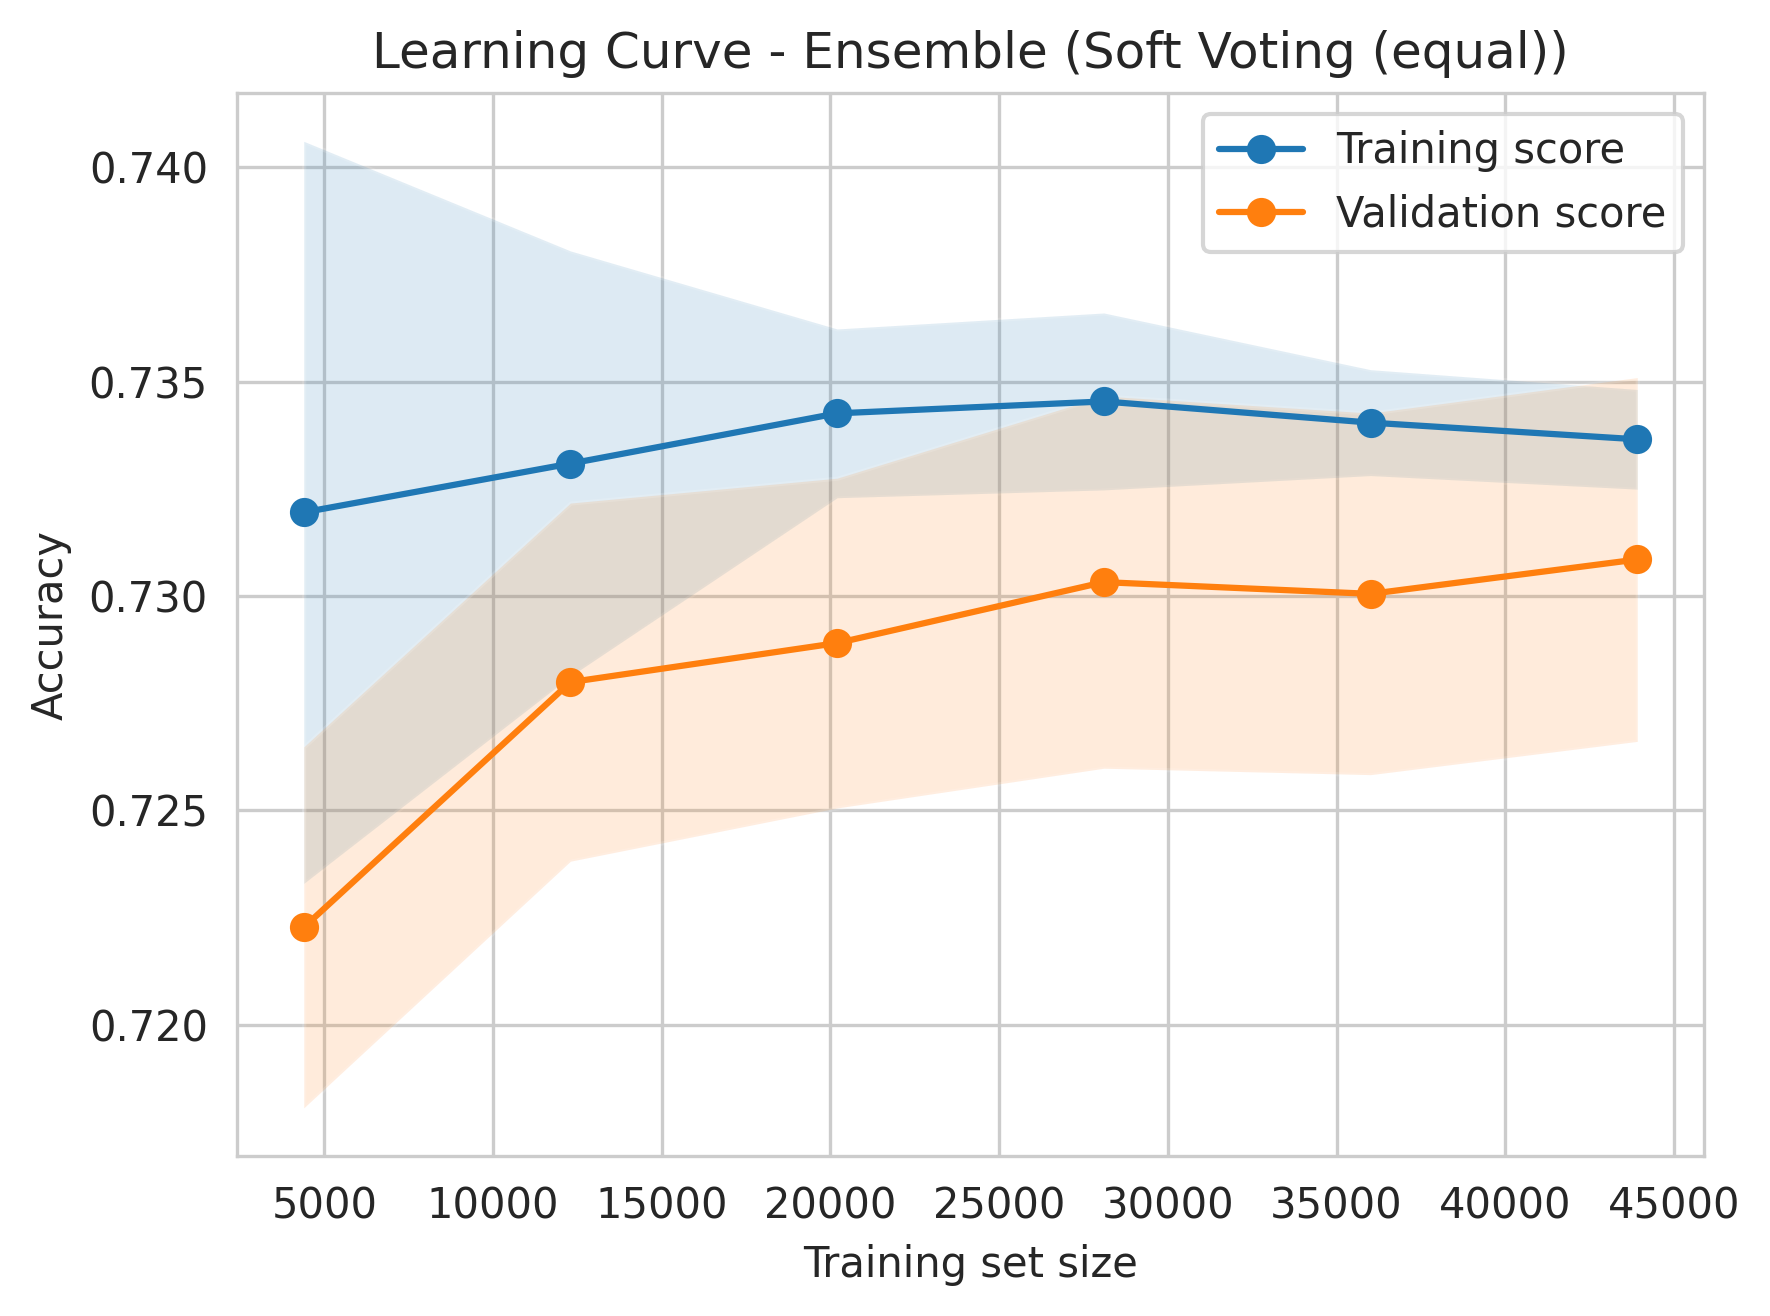

In [ ]:
# @title Ensemble Learning Curve
from IPython.display import Image, display

cached_ensemble_lc = load_checkpoint("ensemble_learning_curve_data")
if cached_ensemble_lc is None:
  plot_learning_curve(
      ensemble,
      X_train, y_train,
      f"Learning Curve - Ensemble ({best_ensemble_name})",
      "learning_curve_ensemble",
  )
  save_checkpoint(True, "ensemble_learning_curve_data")
else:
  print("Learning curve already generated, loading saved image")
  display(Image(f"{MODEL_GRAPHS_PATH}/learning_curve_ensemble.png",width=600))

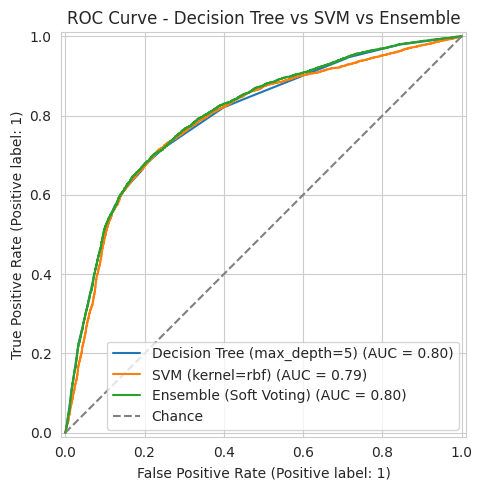

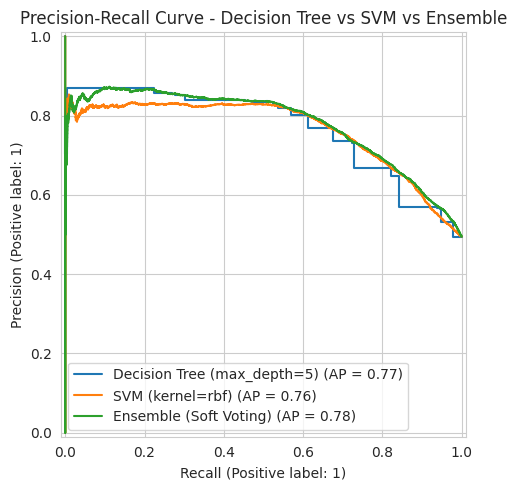

In [ ]:
# @title ROC Curve and Precision-Recall Curve (DT vs SVM vs Ensemble)
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# ROC Curve comparison
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, dt_proba, name=f"Decision Tree (max_depth={best_depth})", ax=ax)
RocCurveDisplay.from_predictions(y_test, svm_score, name=f"SVM (kernel={best_kernel})", ax=ax)
RocCurveDisplay.from_predictions(y_test, ensemble_proba, name="Ensemble (Soft Voting)", ax=ax)

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_title("ROC Curve - Decision Tree vs SVM vs Ensemble")
ax.legend()
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/roc_curve_comparison_ensemble.png", dpi=300, bbox_inches="tight")
plt.show()

print()

# Precision-Recall Curve comparison
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, dt_proba, name=f"Decision Tree (max_depth={best_depth})", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, svm_score, name=f"SVM (kernel={best_kernel})", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, ensemble_proba, name="Ensemble (Soft Voting)", ax=ax)
ax.set_title("Precision-Recall Curve - Decision Tree vs SVM vs Ensemble")
ax.legend()
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/precision_recall_curve_comparison_ensemble.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# @title Check Required Objects Before SHAP

required_objects = [
    "SEED",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "dt_final",
    "svm_final",
    "ensemble",
    "scaler"
]

print("Checking objects required for SHAP:\n")

all_ready = True

for obj in required_objects:
    if obj in globals():
        value = globals()[obj]

        if hasattr(value, "shape"):
            print(f"✓ {obj:<12} exists | shape = {value.shape}")
        else:
            print(f"✓ {obj:<12} exists | type = {type(value).__name__}")
    else:
        print(f"✗ {obj:<12} MISSING")
        all_ready = False

if all_ready:
    print("\n✓ Everything required for SHAP is ready.")
else:
    print("\n✗ Some required objects are missing. Do not run SHAP yet.")

print("X_train columns:")
print(X_train.columns.tolist())

print("\nX_test columns:")
print(X_test.columns.tolist())

print("\nNumber of features:", X_train.shape[1])

Checking objects required for SHAP:

✓ SEED         exists | type = int
✓ X_train      exists | shape = (54888, 10)
✓ X_test       exists | shape = (13722, 10)
✓ y_train      exists | shape = (54888,)
✓ y_test       exists | shape = (13722,)
✓ dt_final     exists | type = DecisionTreeClassifier
✓ svm_final    exists | type = SVC
✓ ensemble     exists | type = VotingClassifier
✓ scaler       exists | type = StandardScaler

✓ Everything required for SHAP is ready.
X_train columns:
['age_years', 'gender', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'active', 'bmi', 'hypertension']

X_test columns:
['age_years', 'gender', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'active', 'bmi', 'hypertension']

Number of features: 10


In [ ]:
# @title Explainable AI (SHAP) - Setup

# Install SHAP if needed in Google Colab
!pip install -q shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import joblib

# Folder for SHAP figures/results

SHAP_GRAPHS_PATH = "/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs"
os.makedirs(SHAP_GRAPHS_PATH, exist_ok=True)

print(f"SHAP figures will be saved to: {SHAP_GRAPHS_PATH}")

# Feature names

feature_names = list(X_train.columns)

print("\nFeatures used for SHAP:")
for i, feature in enumerate(feature_names, start=1):
    print(f"{i}. {feature}")

# Reproducible SHAP samples
#________________________________________________________
# Model-agnostic SHAP can be computationally expensive,
# especially for the RBF SVM and ensemble.
#
# Therefore:
# - 100 training observations are used as the background set
# - 300 held-out test observations are explained
#
# The same observations are used for all three models so that
# their explanations are directly comparable.

SHAP_BACKGROUND_SIZE = 100
SHAP_EXPLAIN_SIZE = 300

X_shap_background = X_train.sample(
    n=min(SHAP_BACKGROUND_SIZE, len(X_train)),
    random_state=SEED
)

X_shap_test = X_test.sample(
    n=min(SHAP_EXPLAIN_SIZE, len(X_test)),
    random_state=SEED
)

y_shap_test = y_test.loc[X_shap_test.index]

print("\nSHAP background shape:", X_shap_background.shape)
print("SHAP explanation sample shape:", X_shap_test.shape)
print("\nSHAP test-sample class distribution:")
print(y_shap_test.value_counts())
print(y_shap_test.value_counts(normalize=True))

# Keep all SHAP inputs as DataFrames so feature names and
# original clinical units are retained.
X_shap_background = X_shap_background[feature_names].copy()
X_shap_test = X_shap_test[feature_names].copy()

SHAP figures will be saved to: /content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs

Features used for SHAP:
1. age_years
2. gender
3. ap_hi
4. ap_lo
5. cholesterol
6. gluc
7. smoke
8. active
9. bmi
10. hypertension

SHAP background shape: (100, 10)
SHAP explanation sample shape: (300, 10)

SHAP test-sample class distribution:
cardio
0    153
1    147
Name: count, dtype: int64
cardio
0    0.51
1    0.49
Name: proportion, dtype: float64


In [ ]:
# @title SHAP Prediction Functions

# Helper function
# SHAP may pass NumPy arrays instead of DataFrames.
# Convert them back to DataFrames so the feature ordering
# always remains correct.

def to_feature_dataframe(data):
    if isinstance(data, pd.DataFrame):
        return data[feature_names].copy()

    return pd.DataFrame(data, columns=feature_names)


# Decision Tree
def predict_dt_probability(data):
    data_df = to_feature_dataframe(data)

    # Probability of the positive class: CVD = 1
    return dt_final.predict_proba(data_df)[:, 1]


# SVM
def predict_svm_margin(data):
    data_df = to_feature_dataframe(data)

    # svm_final was fitted on scaled data.
    # Scale internally so SHAP can still use the original
    # clinically meaningful feature values.
    data_scaled = scaler.transform(data_df)

    # Final SVM was trained with probability=False,
    # so explain its decision-function margin.
    return svm_final.decision_function(data_scaled)


# Ensemble
def predict_ensemble_probability(data):
    data_df = to_feature_dataframe(data)

    # The voting ensemble can return the probability of CVD = 1
    return ensemble.predict_proba(data_df)[:, 1]


# Quick validation checks
print("Decision Tree output:")
print(predict_dt_probability(X_shap_test.iloc[:5]))

print("\nSVM output:")
print(predict_svm_margin(X_shap_test.iloc[:5]))

print("\nEnsemble output:")
print(predict_ensemble_probability(X_shap_test.iloc[:5]))

Decision Tree output:
[0.81637259 0.86201867 0.86201867 0.76045296 0.12724239]

SVM output:
[ 0.99688611  1.00484118  0.98081387  1.00226014 -1.00780854]

Ensemble output:
[0.80644182 0.83003577 0.82769409 0.77900327 0.19451164]


In [ ]:
# @title Calculate SHAP Values for DT, SVM and Ensemble

# Cache file for SHAP results
SHAP_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_PATH,
    "shap_results.pkl"
)

# Load cached SHAP values if they already exist
if os.path.exists(SHAP_CHECKPOINT_PATH):

    print("Loading cached SHAP results...")

    shap_cache = joblib.load(SHAP_CHECKPOINT_PATH)

    shap_dt = shap_cache["dt"]
    shap_svm = shap_cache["svm"]
    shap_ensemble = shap_cache["ensemble"]
    X_shap_test = shap_cache["X_shap_test"]
    y_shap_test = shap_cache["y_shap_test"]

    print("Cached SHAP results loaded successfully.")

else:

    print("No SHAP cache found.")
    print("Calculating SHAP values...")
    print("The SVM and ensemble may take several minutes.\n")

    # Same background distribution for all three models
    masker = shap.maskers.Independent(
        X_shap_background,
        max_samples=SHAP_BACKGROUND_SIZE
    )

    # 1. Decision Tree

    print("1/3 Explaining Decision Tree...")

    dt_explainer = shap.Explainer(
        predict_dt_probability,
        masker,
        algorithm="permutation",
        feature_names=feature_names
    )

    shap_dt = dt_explainer(
        X_shap_test,
        max_evals=2 * len(feature_names) + 1
    )

    print("Decision Tree SHAP complete.\n")

    # 2. SVM

    print("2/3 Explaining SVM...")

    svm_explainer = shap.Explainer(
        predict_svm_margin,
        masker,
        algorithm="permutation",
        feature_names=feature_names
    )

    shap_svm = svm_explainer(
        X_shap_test,
        max_evals=2 * len(feature_names) + 1
    )

    print("SVM SHAP complete.\n")

    # 3. Ensemble

    print("3/3 Explaining Ensemble...")

    ensemble_explainer = shap.Explainer(
        predict_ensemble_probability,
        masker,
        algorithm="permutation",
        feature_names=feature_names
    )

    shap_ensemble = ensemble_explainer(
        X_shap_test,
        max_evals=2 * len(feature_names) + 1
    )

    print("Ensemble SHAP complete.\n")

    # Save SHAP results so they do not need to be recalculated
    shap_cache = {
        "dt": shap_dt,
        "svm": shap_svm,
        "ensemble": shap_ensemble,
        "X_shap_test": X_shap_test,
        "y_shap_test": y_shap_test
    }

    joblib.dump(shap_cache, SHAP_CHECKPOINT_PATH)

    print("SHAP results cached successfully.")
    print("Saved to:")
    print(SHAP_CHECKPOINT_PATH)


# Final validation
print("\nSHAP calculation finished.")
print("DT SHAP shape:", shap_dt.values.shape)
print("SVM SHAP shape:", shap_svm.values.shape)
print("Ensemble SHAP shape:", shap_ensemble.values.shape)

Loading cached SHAP results...
Cached SHAP results loaded successfully.

SHAP calculation finished.
DT SHAP shape: (300, 10)
SVM SHAP shape: (300, 10)
Ensemble SHAP shape: (300, 10)


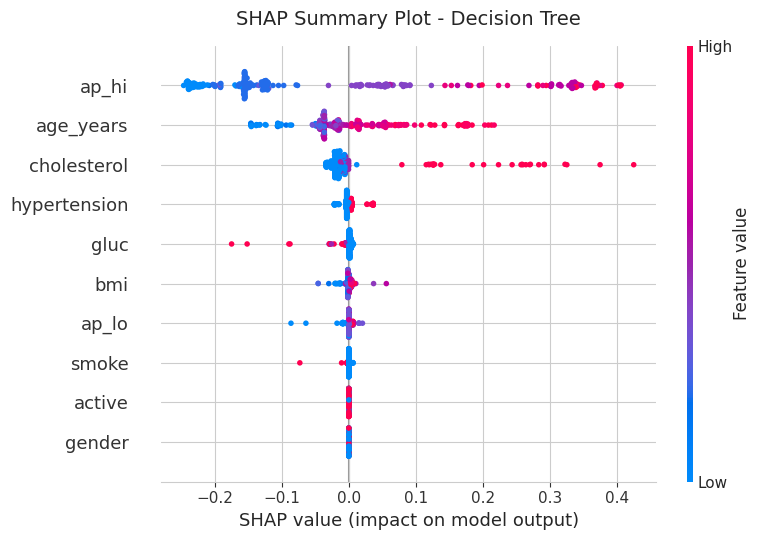

Decision Tree summary plot saved to:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_summary_decision_tree.png


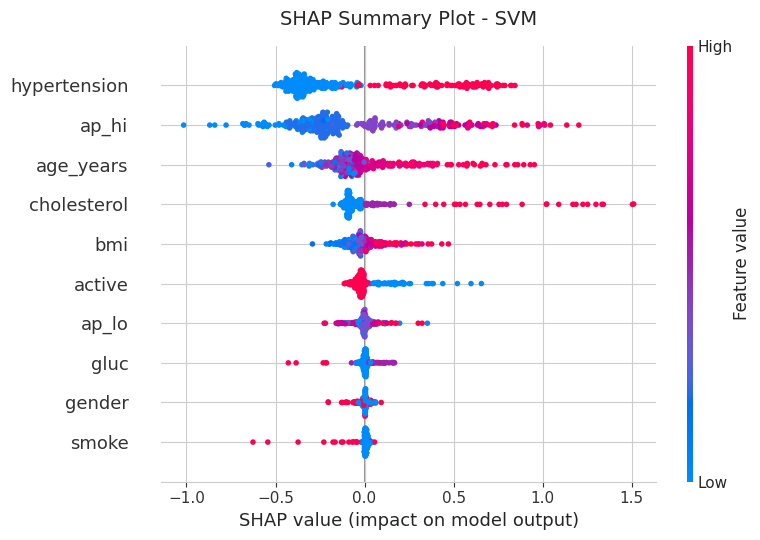

SVM summary plot saved to:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_summary_svm.png


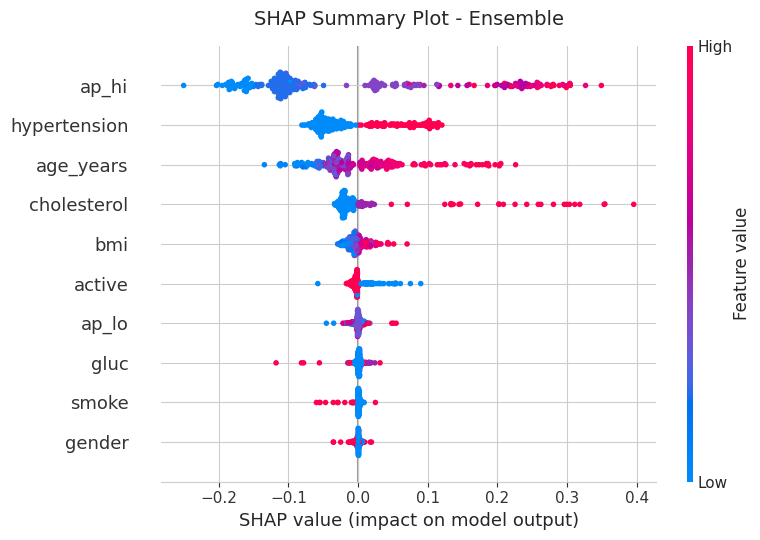

Ensemble summary plot saved to:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_summary_ensemble.png


In [ ]:
# @title SHAP Global Summary Plots

# Decision Tree

shap.summary_plot(
    shap_dt.values,
    X_shap_test,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Summary Plot - Decision Tree",
    fontsize=14,
    pad=15
)

plt.tight_layout()

dt_summary_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_summary_decision_tree.png"
)

plt.savefig(
    dt_summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Decision Tree summary plot saved to:\n{dt_summary_path}")

# SVM

shap.summary_plot(
    shap_svm.values,
    X_shap_test,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Summary Plot - SVM",
    fontsize=14,
    pad=15
)

plt.tight_layout()

svm_summary_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_summary_svm.png"
)

plt.savefig(
    svm_summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"SVM summary plot saved to:\n{svm_summary_path}")

# Ensemble

shap.summary_plot(
    shap_ensemble.values,
    X_shap_test,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Summary Plot - Ensemble",
    fontsize=14,
    pad=15
)

plt.tight_layout()

ensemble_summary_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_summary_ensemble.png"
)

plt.savefig(
    ensemble_summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Ensemble summary plot saved to:\n{ensemble_summary_path}")

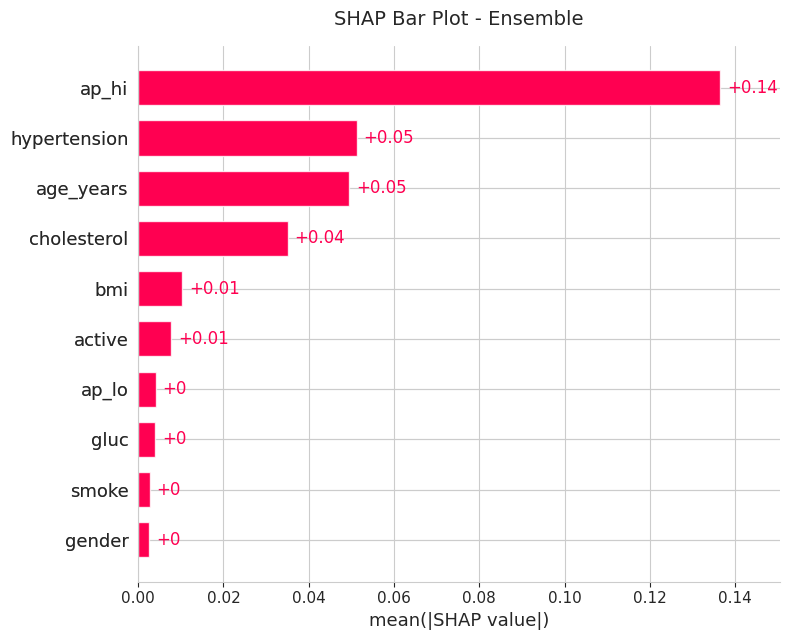

Ensemble SHAP bar plot saved to:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_bar_ensemble.png


In [ ]:
# @title SHAP Bar Plot - Ensemble

# Global SHAP bar plot for the final Ensemble model
shap.plots.bar(
    shap_ensemble,
    max_display=len(feature_names),
    show=False
)

plt.title(
    "SHAP Bar Plot - Ensemble",
    fontsize=14,
    pad=15
)

plt.tight_layout()

ensemble_bar_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_bar_ensemble.png"
)

plt.savefig(
    ensemble_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Ensemble SHAP bar plot saved to:\n"
    f"{ensemble_bar_path}"
)

In [ ]:
# @title Cross-Model SHAP Feature Importance Comparison

# Calculate mean absolute SHAP importance
dt_mean_abs = np.abs(shap_dt.values).mean(axis=0)
svm_mean_abs = np.abs(shap_svm.values).mean(axis=0)
ensemble_mean_abs = np.abs(shap_ensemble.values).mean(axis=0)

shap_comparison_df = pd.DataFrame({
    "Feature": feature_names,
    "Decision Tree Raw Mean |SHAP|": dt_mean_abs,
    "SVM Raw Mean |SHAP|": svm_mean_abs,
    "Ensemble Raw Mean |SHAP|": ensemble_mean_abs
})

# Normalise each model separately
#_________________________________________________________
#
# Raw SHAP magnitudes cannot fairly be compared directly
# across all three models because:
#
# Decision Tree -> predicted probability
# SVM           -> decision-function margin
# Ensemble      -> predicted probability
#
# Therefore we convert each model's feature importances into
# percentages of that model's total SHAP importance.

shap_comparison_df["Decision Tree (%)"] = (
    shap_comparison_df["Decision Tree Raw Mean |SHAP|"]
    / shap_comparison_df["Decision Tree Raw Mean |SHAP|"].sum()
    * 100
)

shap_comparison_df["SVM (%)"] = (
    shap_comparison_df["SVM Raw Mean |SHAP|"]
    / shap_comparison_df["SVM Raw Mean |SHAP|"].sum()
    * 100
)

shap_comparison_df["Ensemble (%)"] = (
    shap_comparison_df["Ensemble Raw Mean |SHAP|"]
    / shap_comparison_df["Ensemble Raw Mean |SHAP|"].sum()
    * 100
)


# Average relative importance across the three models
shap_comparison_df["Average Importance (%)"] = (
    shap_comparison_df[
        [
            "Decision Tree (%)",
            "SVM (%)",
            "Ensemble (%)"
        ]
    ].mean(axis=1)
)


# Sort by overall average importance
shap_comparison_df = (
    shap_comparison_df
    .sort_values(
        "Average Importance (%)",
        ascending=False
    )
    .reset_index(drop=True)
)


# Display clean comparison table
display(
    shap_comparison_df[
        [
            "Feature",
            "Decision Tree (%)",
            "SVM (%)",
            "Ensemble (%)",
            "Average Importance (%)"
        ]
    ].round(2)
)

# Save results

comparison_csv_path = (
    "/content/drive/MyDrive/Cardiovascular Disease/"
    "shap_cross_model_comparison.csv"
)

shap_comparison_df.to_csv(
    comparison_csv_path,
    index=False
)

print(
    f"\nCross-model SHAP table saved to:\n"
    f"{comparison_csv_path}"
)

,Feature,Decision Tree (%),SVM (%),Ensemble (%),Average Importance (%)
0,ap_hi,63.87,27.20,44.94,45.33
1,age_years,18.94,13.66,16.30,16.30
2,hypertension,2.10,29.36,16.87,16.11
3,cholesterol,11.58,11.90,11.54,11.67
4,bmi,1.10,5.82,3.40,3.44
5,active,0.00,4.50,2.57,2.36
6,ap_lo,0.76,2.79,1.36,1.64
7,gluc,1.46,1.77,1.29,1.51
8,smoke,0.19,1.45,0.88,0.84
9,gender,0.00,1.57,0.85,0.81



Cross-model SHAP table saved to:
/content/drive/MyDrive/Cardiovascular Disease/shap_cross_model_comparison.csv


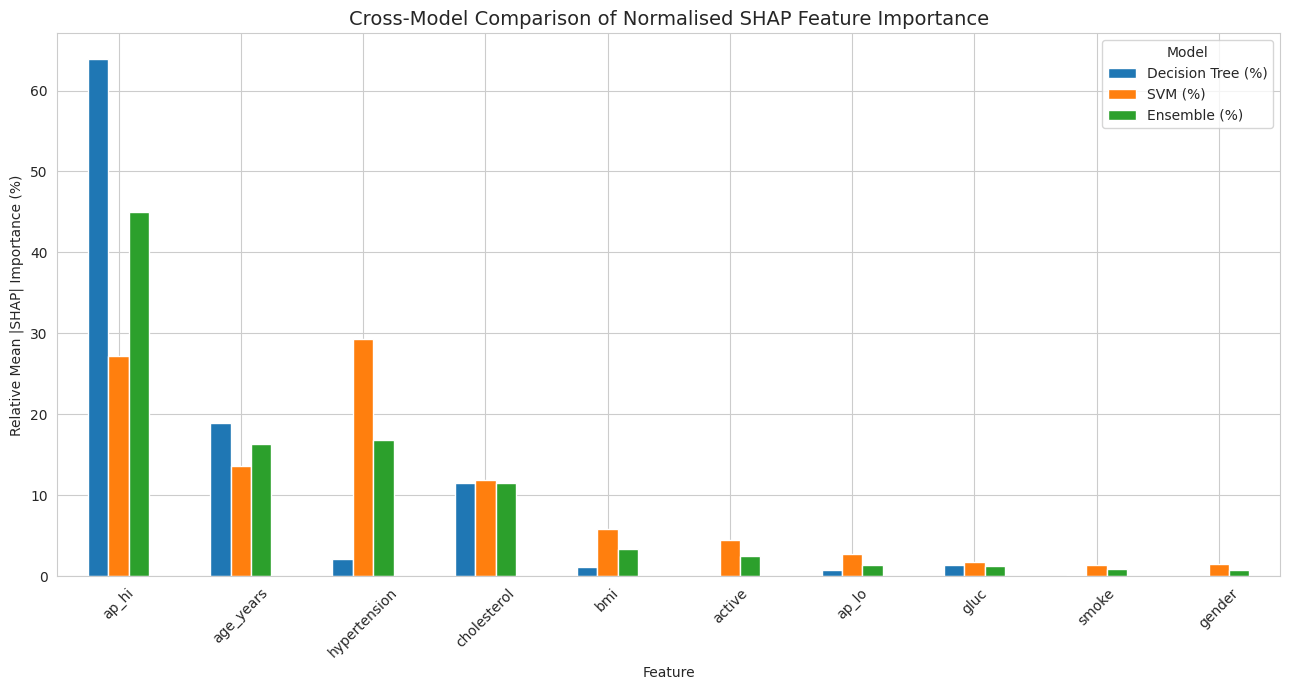

Cross-model comparison plot saved to:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_cross_model_comparison.png


In [ ]:
# @title Cross-Model SHAP Comparison Plot

comparison_plot_df = (
    shap_comparison_df
    .set_index("Feature")[
        [
            "Decision Tree (%)",
            "SVM (%)",
            "Ensemble (%)"
        ]
    ]
)

ax = comparison_plot_df.plot(
    kind="bar",
    figsize=(13, 7)
)

ax.set_title(
    "Cross-Model Comparison of Normalised SHAP Feature Importance",
    fontsize=14
)

ax.set_xlabel("Feature")
ax.set_ylabel("Relative Mean |SHAP| Importance (%)")

ax.tick_params(
    axis="x",
    rotation=45
)

ax.legend(
    title="Model"
)

plt.tight_layout()

comparison_plot_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_cross_model_comparison.png"
)

plt.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Cross-model comparison plot saved to:\n"
    f"{comparison_plot_path}"
)

In [ ]:
# @title Top SHAP Features by Model

print("=" * 60)
print("TOP 5 SHAP FEATURES BY MODEL")
print("=" * 60)


print("\nDECISION TREE")
display(
    shap_comparison_df[
        ["Feature", "Decision Tree (%)"]
    ]
    .sort_values(
        "Decision Tree (%)",
        ascending=False
    )
    .head(5)
    .round(2)
)


print("\nSVM")
display(
    shap_comparison_df[
        ["Feature", "SVM (%)"]
    ]
    .sort_values(
        "SVM (%)",
        ascending=False
    )
    .head(5)
    .round(2)
)


print("\nENSEMBLE")
display(
    shap_comparison_df[
        ["Feature", "Ensemble (%)"]
    ]
    .sort_values(
        "Ensemble (%)",
        ascending=False
    )
    .head(5)
    .round(2)
)

TOP 5 SHAP FEATURES BY MODEL

DECISION TREE


,Feature,Decision Tree (%)
0,ap_hi,63.87
1,age_years,18.94
3,cholesterol,11.58
2,hypertension,2.10
7,gluc,1.46



SVM


,Feature,SVM (%)
2,hypertension,29.36
0,ap_hi,27.20
1,age_years,13.66
3,cholesterol,11.90
4,bmi,5.82



ENSEMBLE


,Feature,Ensemble (%)
0,ap_hi,44.94
2,hypertension,16.87
1,age_years,16.30
3,cholesterol,11.54
4,bmi,3.40


Feature selected for dependence analysis: ap_hi


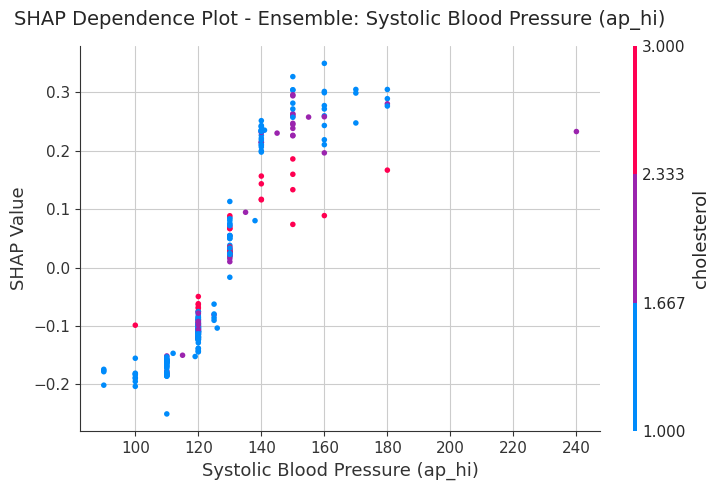


Dependence plot saved to:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_dependence_ensemble_ap_hi.png


In [ ]:
# @title SHAP Dependence Plot - Ensemble

# ap_hi is selected because it is the highest-ranking
# continuous feature in the Ensemble SHAP analysis.

dependence_feature = "ap_hi"

print(
    f"Feature selected for dependence analysis: "
    f"{dependence_feature}"
)

shap.dependence_plot(
    dependence_feature,
    shap_ensemble.values,
    X_shap_test,
    feature_names=feature_names,
    interaction_index="auto",
    show=False
)

plt.title(
    "SHAP Dependence Plot - Ensemble: Systolic Blood Pressure (ap_hi)",
    fontsize=14,
    pad=15
)

plt.xlabel("Systolic Blood Pressure (ap_hi)")
plt.ylabel("SHAP Value")

plt.tight_layout()

dependence_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_dependence_ensemble_ap_hi.png"
)

plt.savefig(
    dependence_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"\nDependence plot saved to:\n"
    f"{dependence_path}"
)

In [ ]:
# @title Select Patients for Local SHAP Explanations

# Ensemble probabilities and predictions for the same
# 300-patient SHAP test sample

shap_subset_proba = predict_ensemble_probability(X_shap_test)

shap_subset_pred = (
    shap_subset_proba >= 0.5
).astype(int)


# Build patient-selection table
local_case_df = pd.DataFrame(
    {
        "Actual": y_shap_test.values,
        "Predicted": shap_subset_pred,
        "CVD Probability": shap_subset_proba
    },
    index=X_shap_test.index
)


# Find correctly classified CVD patients
correct_cvd_positions = np.where(
    (local_case_df["Actual"].values == 1) &
    (local_case_df["Predicted"].values == 1)
)[0]


# Find correctly classified No-CVD patients
correct_no_cvd_positions = np.where(
    (local_case_df["Actual"].values == 0) &
    (local_case_df["Predicted"].values == 0)
)[0]


if len(correct_cvd_positions) == 0:
    raise ValueError(
        "No correctly predicted CVD patient was found "
        "in the SHAP sample."
    )

if len(correct_no_cvd_positions) == 0:
    raise ValueError(
        "No correctly predicted No-CVD patient was found "
        "in the SHAP sample."
    )


# Select a clear representative CVD prediction:
# correctly classified patient with highest CVD probability
cvd_position = correct_cvd_positions[
    np.argmax(
        shap_subset_proba[correct_cvd_positions]
    )
]


# Select a clear representative No-CVD prediction:
# correctly classified patient with lowest CVD probability
no_cvd_position = correct_no_cvd_positions[
    np.argmin(
        shap_subset_proba[correct_no_cvd_positions]
    )
]


print("=" * 60)
print("SELECTED PATIENTS FOR LOCAL SHAP EXPLANATIONS")
print("=" * 60)

print("\nCVD patient:")
display(
    local_case_df.iloc[[cvd_position]]
)

print("\nCVD patient feature values:")
display(
    X_shap_test.iloc[[cvd_position]]
)


print("\nNo-CVD patient:")
display(
    local_case_df.iloc[[no_cvd_position]]
)

print("\nNo-CVD patient feature values:")
display(
    X_shap_test.iloc[[no_cvd_position]]
)

SELECTED PATIENTS FOR LOCAL SHAP EXPLANATIONS

CVD patient:


,Actual,Predicted,CVD Probability
55767,1,1,0.866742



CVD patient feature values:


,age_years,gender,ap_hi,ap_lo,cholesterol,gluc,smoke,active,bmi,hypertension
55767,60.219028,0,140,80,2,1,0,1,24.03461,1



No-CVD patient:


,Actual,Predicted,CVD Probability
36048,0,0,0.134014



No-CVD patient feature values:


,age_years,gender,ap_hi,ap_lo,cholesterol,gluc,smoke,active,bmi,hypertension
36048,46.009582,0,110,90,1,1,0,1,25.777778,1


LOCAL SHAP EXPLANATION - CVD PATIENT

Patient feature values:


,age_years,gender,ap_hi,ap_lo,cholesterol,gluc,smoke,active,bmi,hypertension
55767,60.219028,0,140,80,2,1,0,1,24.03461,1



Actual class: 1
Predicted CVD probability: 0.8667


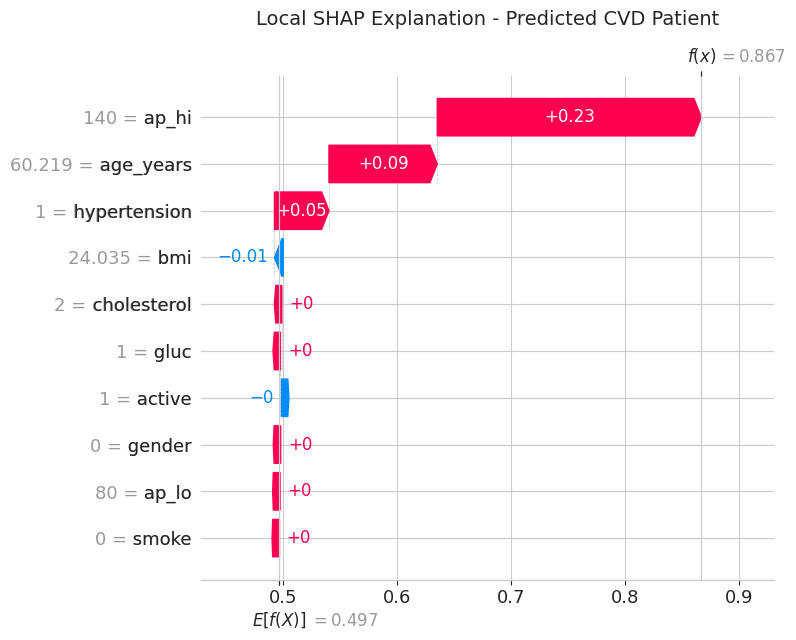


CVD patient waterfall plot saved to:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_local_cvd_patient.png

LOCAL SHAP EXPLANATION - NO-CVD PATIENT

Patient feature values:


,age_years,gender,ap_hi,ap_lo,cholesterol,gluc,smoke,active,bmi,hypertension
36048,46.009582,0,110,90,1,1,0,1,25.777778,1



Actual class: 0
Predicted CVD probability: 0.134


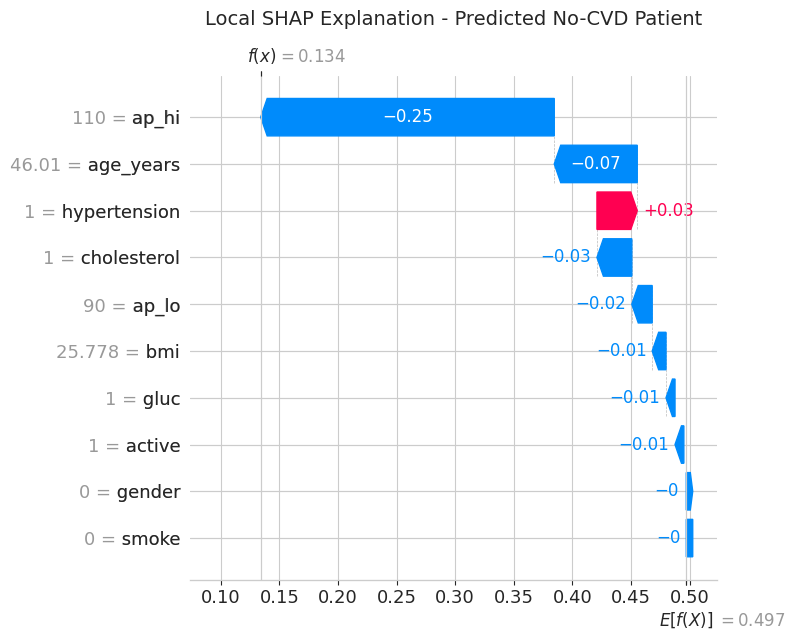


No-CVD patient waterfall plot saved to:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_local_no_cvd_patient.png


In [ ]:
# @title Local SHAP Explanations - Ensemble

# CVD Patient

print("=" * 60)
print("LOCAL SHAP EXPLANATION - CVD PATIENT")
print("=" * 60)

print("\nPatient feature values:")
display(X_shap_test.iloc[[cvd_position]])

print(
    "\nActual class:",
    int(y_shap_test.iloc[cvd_position])
)

print(
    "Predicted CVD probability:",
    round(
        predict_ensemble_probability(
            X_shap_test.iloc[[cvd_position]]
        )[0],
        4
    )
)

shap.plots.waterfall(
    shap_ensemble[cvd_position],
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Local SHAP Explanation - Predicted CVD Patient",
    fontsize=14,
    pad=15
)

plt.tight_layout()

cvd_local_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_local_cvd_patient.png"
)

plt.savefig(
    cvd_local_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"\nCVD patient waterfall plot saved to:\n"
    f"{cvd_local_path}"
)


# NO-CVD Patient

print("\n" + "=" * 60)
print("LOCAL SHAP EXPLANATION - NO-CVD PATIENT")
print("=" * 60)

print("\nPatient feature values:")
display(X_shap_test.iloc[[no_cvd_position]])

print(
    "\nActual class:",
    int(y_shap_test.iloc[no_cvd_position])
)

print(
    "Predicted CVD probability:",
    round(
        predict_ensemble_probability(
            X_shap_test.iloc[[no_cvd_position]]
        )[0],
        4
    )
)

shap.plots.waterfall(
    shap_ensemble[no_cvd_position],
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Local SHAP Explanation - Predicted No-CVD Patient",
    fontsize=14,
    pad=15
)

plt.tight_layout()

no_cvd_local_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_local_no_cvd_patient.png"
)

plt.savefig(
    no_cvd_local_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"\nNo-CVD patient waterfall plot saved to:\n"
    f"{no_cvd_local_path}"
)

CROSS-MODEL LOCAL SHAP COMPARISON

Same patient explained by all three models:



,age_years,gender,ap_hi,ap_lo,cholesterol,gluc,smoke,active,bmi,hypertension
55767,60.219028,0,140,80,2,1,0,1,24.03461,1



Actual class: 1
Decision Tree predicted CVD probability: 0.936
SVM decision-function score: 1.0019
Ensemble predicted CVD probability: 0.8667


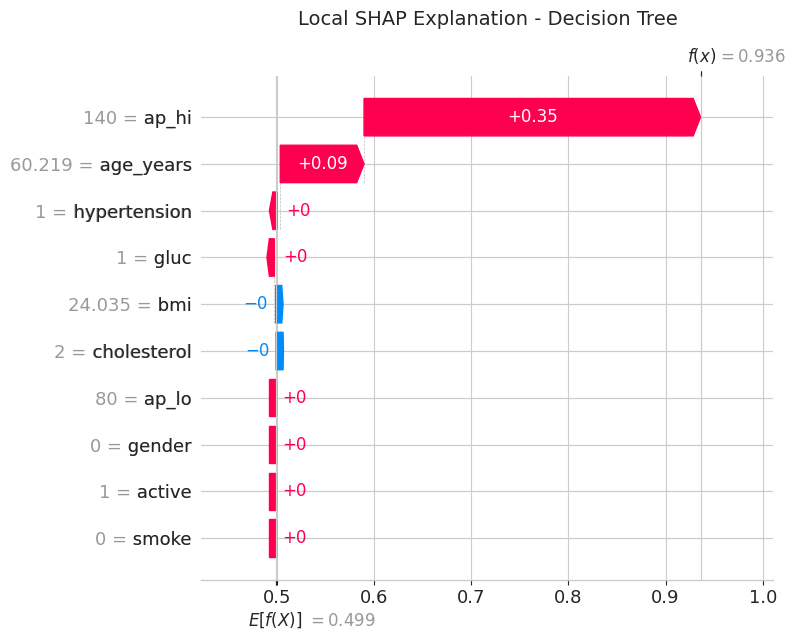

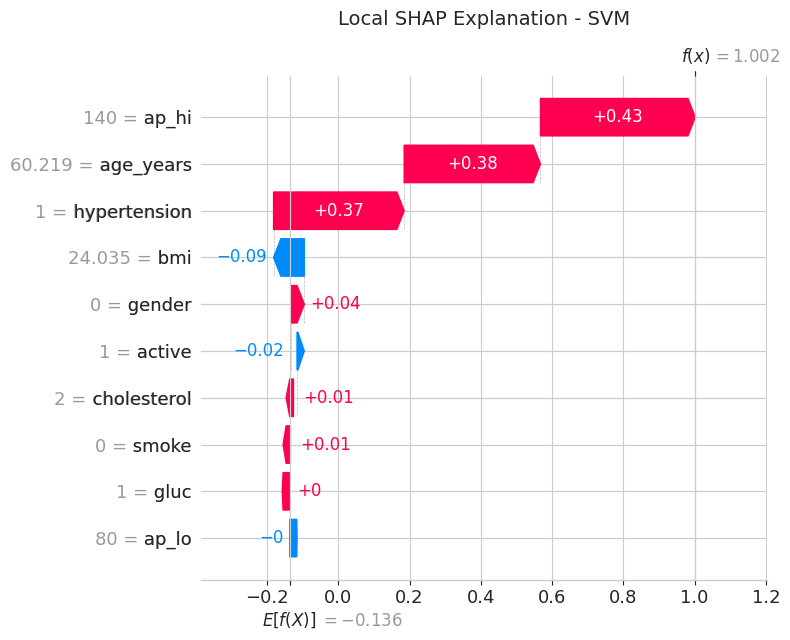

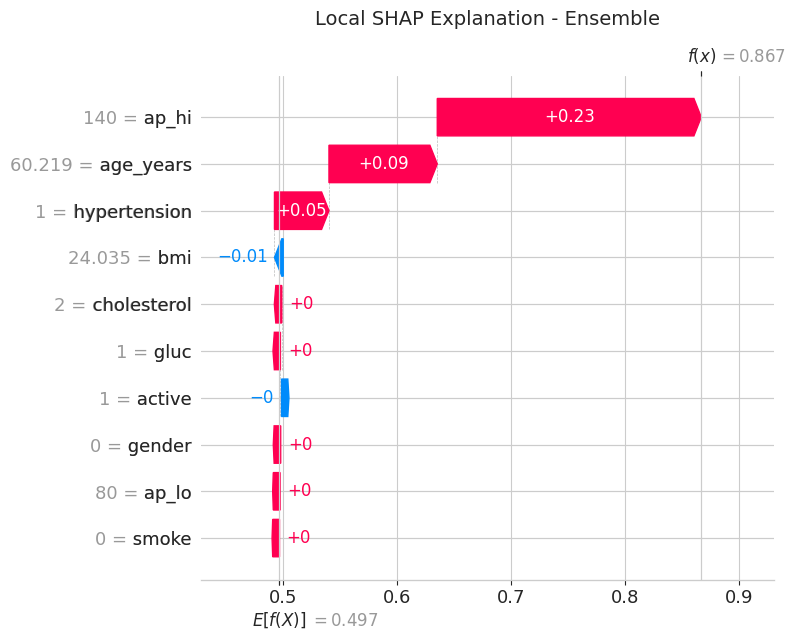


Plots saved successfully:
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_local_comparison_decision_tree.png
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_local_comparison_svm.png
/content/drive/MyDrive/Cardiovascular Disease/SHAP Graphs/shap_local_comparison_ensemble.png


In [ ]:
# @title Cross-Model Local SHAP Comparison - Same CVD Patient

patient_position = cvd_position

print("=" * 65)
print("CROSS-MODEL LOCAL SHAP COMPARISON")
print("=" * 65)

print("\nSame patient explained by all three models:\n")

display(X_shap_test.iloc[[patient_position]])

actual_class = int(
    y_shap_test.iloc[patient_position]
)

dt_probability = predict_dt_probability(
    X_shap_test.iloc[[patient_position]]
)[0]

svm_margin = predict_svm_margin(
    X_shap_test.iloc[[patient_position]]
)[0]

ensemble_probability = predict_ensemble_probability(
    X_shap_test.iloc[[patient_position]]
)[0]


print("\nActual class:", actual_class)

print(
    "Decision Tree predicted CVD probability:",
    round(dt_probability, 4)
)

print(
    "SVM decision-function score:",
    round(svm_margin, 4)
)

print(
    "Ensemble predicted CVD probability:",
    round(ensemble_probability, 4)
)


# Decision Tree

shap.plots.waterfall(
    shap_dt[patient_position],
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Local SHAP Explanation - Decision Tree",
    fontsize=14,
    pad=15
)

plt.tight_layout()

dt_local_compare_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_local_comparison_decision_tree.png"
)

plt.savefig(
    dt_local_compare_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# SVM

shap.plots.waterfall(
    shap_svm[patient_position],
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Local SHAP Explanation - SVM",
    fontsize=14,
    pad=15
)

plt.tight_layout()

svm_local_compare_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_local_comparison_svm.png"
)

plt.savefig(
    svm_local_compare_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Ensemble

shap.plots.waterfall(
    shap_ensemble[patient_position],
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Local SHAP Explanation - Ensemble",
    fontsize=14,
    pad=15
)

plt.tight_layout()

ensemble_local_compare_path = os.path.join(
    SHAP_GRAPHS_PATH,
    "shap_local_comparison_ensemble.png"
)

plt.savefig(
    ensemble_local_compare_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nPlots saved successfully:")
print(dt_local_compare_path)
print(svm_local_compare_path)
print(ensemble_local_compare_path)

In [ ]:
# @title SHAP Results Summary

def top_features(model_column, n=5):
    return (
        shap_comparison_df[
            ["Feature", model_column]
        ]
        .sort_values(
            model_column,
            ascending=False
        )
        .head(n)
        .reset_index(drop=True)
    )


print("=" * 65)
print("SHAP RESULTS SUMMARY")
print("=" * 65)

print("\n1. DECISION TREE - TOP 5 FEATURES")
display(
    top_features(
        "Decision Tree (%)"
    ).round(2)
)

print("\n2. SVM - TOP 5 FEATURES")
display(
    top_features(
        "SVM (%)"
    ).round(2)
)

print("\n3. ENSEMBLE - TOP 5 FEATURES")
display(
    top_features(
        "Ensemble (%)"
    ).round(2)
)


print("\n4. DEPENDENCE ANALYSIS")
print(
    "Feature analysed:",
    dependence_feature
)


print("\n5. LOCAL CVD CASE")
print(
    "Actual class:",
    int(y_shap_test.iloc[cvd_position])
)
print(
    "Ensemble CVD probability:",
    round(
        predict_ensemble_probability(
            X_shap_test.iloc[[cvd_position]]
        )[0],
        4
    )
)


print("\n6. LOCAL NO-CVD CASE")
print(
    "Actual class:",
    int(y_shap_test.iloc[no_cvd_position])
)
print(
    "Ensemble CVD probability:",
    round(
        predict_ensemble_probability(
            X_shap_test.iloc[[no_cvd_position]]
        )[0],
        4
    )
)


print("\n7. CROSS-MODEL CVD CASE")
print(
    "Decision Tree probability:",
    round(dt_probability, 4)
)
print(
    "SVM decision score:",
    round(svm_margin, 4)
)
print(
    "Ensemble probability:",
    round(ensemble_probability, 4)
)


print("\n8. SHAP SAMPLE")
print(
    "Background observations:",
    len(X_shap_background)
)
print(
    "Explained test observations:",
    len(X_shap_test)
)

print("\nSHAP analysis complete.")

SHAP RESULTS SUMMARY

1. DECISION TREE - TOP 5 FEATURES


,Feature,Decision Tree (%)
0,ap_hi,63.87
1,age_years,18.94
2,cholesterol,11.58
3,hypertension,2.10
4,gluc,1.46



2. SVM - TOP 5 FEATURES


,Feature,SVM (%)
0,hypertension,29.36
1,ap_hi,27.20
2,age_years,13.66
3,cholesterol,11.90
4,bmi,5.82



3. ENSEMBLE - TOP 5 FEATURES


,Feature,Ensemble (%)
0,ap_hi,44.94
1,hypertension,16.87
2,age_years,16.30
3,cholesterol,11.54
4,bmi,3.40



4. DEPENDENCE ANALYSIS
Feature analysed: ap_hi

5. LOCAL CVD CASE
Actual class: 1
Ensemble CVD probability: 0.8667

6. LOCAL NO-CVD CASE
Actual class: 0
Ensemble CVD probability: 0.134

7. CROSS-MODEL CVD CASE
Decision Tree probability: 0.936
SVM decision score: 1.0019
Ensemble probability: 0.8667

8. SHAP SAMPLE
Background observations: 100
Explained test observations: 300

SHAP analysis complete.


               Comparison   Metric  Mean A  Mean B  Mean diff (A-B)  Shapiro-Wilk p  Normal?          Test  Statistic  p-value  Significant (α=0.05)
Ensemble vs Decision Tree accuracy  0.7303  0.7266           0.0037          0.6631     True Paired t-test     2.2679   0.0859                 False
Ensemble vs Decision Tree       f1  0.7056  0.7035           0.0022          0.6262     True Paired t-test     0.8171   0.4597                 False
          Ensemble vs SVM accuracy  0.7303  0.7273           0.0030          0.1313     True Paired t-test     4.6182   0.0099                  True
          Ensemble vs SVM       f1  0.7056  0.7004           0.0052          0.8462     True Paired t-test     4.9397   0.0078                  True
     SVM vs Decision Tree accuracy  0.7273  0.7266           0.0007          0.3529     True Paired t-test     0.4044   0.7066                 False
     SVM vs Decision Tree       f1  0.7004  0.7035          -0.0031          0.8978     True Paired t-test

/tmp/ipykernel_28183/4229860972.py:91: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([fold_scores[metric][k] for k in ['Decision Tree', 'SVM', 'Ensemble']],
/tmp/ipykernel_28183/4229860972.py:91: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([fold_scores[metric][k] for k in ['Decision Tree', 'SVM', 'Ensemble']],


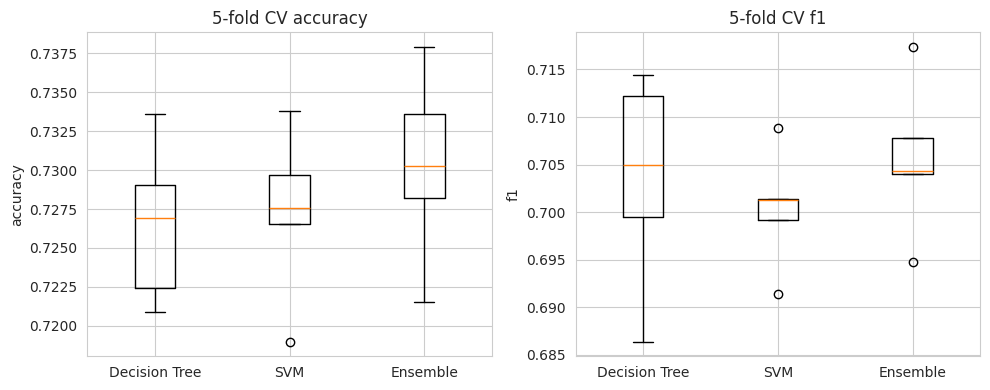

In [ ]:
# @title Statistical Analysis: Ensemble vs Individual Models (5 CV folds)
from scipy import stats
import numpy as np
import pandas as pd

ALPHA = 0.05

# Pull per-fold scores out of ensemble_cv_df
def get_folds(df, model_name, col):
    row = df[df['model'] == model_name].iloc[0]
    return np.asarray(row[col], dtype=float)

ens_name = [m for m in ensemble_cv_df['model'] if m.startswith("Ensemble")][0]

fold_scores = {
    'accuracy': {
        'Decision Tree': get_folds(ensemble_cv_df, 'Decision Tree', 'acc_folds'),
        'SVM':           get_folds(ensemble_cv_df, 'SVM', 'acc_folds'),
        'Ensemble':      get_folds(ensemble_cv_df, ens_name, 'acc_folds'),
    },
    'f1': {
        'Decision Tree': get_folds(ensemble_cv_df, 'Decision Tree', 'f1_folds'),
        'SVM':           get_folds(ensemble_cv_df, 'SVM', 'f1_folds'),
        'Ensemble':      get_folds(ensemble_cv_df, ens_name, 'f1_folds'),
    },
}

def compare(a_name, b_name, metric):
    a = fold_scores[metric][a_name]
    b = fold_scores[metric][b_name]
    diff = a - b

    # Step 2: normality of the paired differences
    if np.ptp(diff) == 0:
        sw_p = np.nan          # identical differences, Shapiro undefined
        normal = False
    else:
        sw_stat, sw_p = stats.shapiro(diff)
        normal = sw_p > ALPHA

    # Steps 3/4: choose the test
    if normal:
        test_name = "Paired t-test"
        stat, p = stats.ttest_rel(a, b)
    else:
        test_name = "Wilcoxon signed-rank"
        if np.all(diff == 0):
            stat, p = np.nan, 1.0
        else:
            stat, p = stats.wilcoxon(a, b)   # two-sided

    return {
        'Comparison': f"{a_name} vs {b_name}",
        'Metric': metric,
        'Mean A': a.mean(), 'Mean B': b.mean(),
        'Mean diff (A-B)': diff.mean(),
        'Shapiro-Wilk p': sw_p,
        'Normal?': normal,
        'Test': test_name,
        'Statistic': stat,
        'p-value': p,
        f'Significant (α={ALPHA})': p < ALPHA,
    }

comparisons = [
    ('Ensemble', 'Decision Tree'),
    ('Ensemble', 'SVM'),
    ('SVM', 'Decision Tree'),   # optional extra
]

stats_rows = [compare(a, b, m) for (a, b) in comparisons for m in ['accuracy', 'f1']]
stats_df = pd.DataFrame(stats_rows)
pd.set_option('display.width', 200)
print(stats_df.round(4).to_string(index=False))

# Per-fold table (nice for the report appendix)
fold_table = pd.DataFrame({
    'Fold': range(1, 6),
    'DT acc': fold_scores['accuracy']['Decision Tree'],
    'SVM acc': fold_scores['accuracy']['SVM'],
    'Ens acc': fold_scores['accuracy']['Ensemble'],
    'DT F1': fold_scores['f1']['Decision Tree'],
    'SVM F1': fold_scores['f1']['SVM'],
    'Ens F1': fold_scores['f1']['Ensemble'],
})
print("\n", fold_table.round(4).to_string(index=False))

# Boxplot of fold scores
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ['accuracy', 'f1']):
    ax.boxplot([fold_scores[metric][k] for k in ['Decision Tree', 'SVM', 'Ensemble']],
               labels=['Decision Tree', 'SVM', 'Ensemble'])
    ax.set_title(f'5-fold CV {metric}')
    ax.set_ylabel(metric)
fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/stat_fold_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

stats_df.to_csv(f"{MODEL_GRAPHS_PATH}/stat_tests.csv", index=False)

=== 5-fold CV ACCURACY ===
        Decision Tree     SVM  Ensemble
Fold 1         0.7269  0.7265    0.7303
Fold 2         0.7209  0.7190    0.7215
Fold 3         0.7224  0.7275    0.7282
Fold 4         0.7336  0.7297    0.7336
Fold 5         0.7291  0.7338    0.7379
Mean           0.7266  0.7273    0.7303
Std            0.0046  0.0049    0.0055

=== 5-fold CV F1 ===
        Decision Tree     SVM  Ensemble
Fold 1         0.7050  0.6991    0.7043
Fold 2         0.6864  0.6913    0.6948
Fold 3         0.6995  0.7014    0.7040
Fold 4         0.7144  0.7013    0.7078
Fold 5         0.7122  0.7088    0.7174
Mean           0.7035  0.7004    0.7056
Std            0.0101  0.0056    0.0073


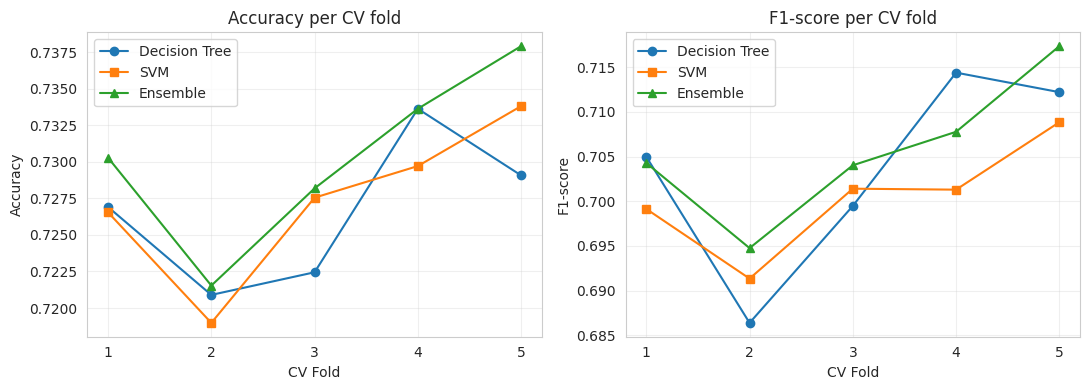

In [ ]:
# @title Per-fold CV scores: Decision Tree vs SVM vs Ensemble
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model_order = ['Decision Tree', 'SVM', 'Ensemble']

def build_fold_table(metric):
    df = pd.DataFrame(
        {m: fold_scores[metric][m] for m in model_order},
        index=[f"Fold {i}" for i in range(1, 6)]
    )
    df.loc['Mean'] = df.iloc[:5].mean()
    df.loc['Std']  = df.iloc[:5].std(ddof=0)   # ddof=0 matches the earlier CV summaries
    return df

acc_fold_df = build_fold_table('accuracy')
f1_fold_df  = build_fold_table('f1')

print("=== 5-fold CV ACCURACY ===")
print(acc_fold_df.round(4).to_string())
print("\n=== 5-fold CV F1 ===")
print(f1_fold_df.round(4).to_string())

# Save for the report appendix
acc_fold_df.round(4).to_csv(f"{MODEL_GRAPHS_PATH}/fold_scores_accuracy.csv")
f1_fold_df.round(4).to_csv(f"{MODEL_GRAPHS_PATH}/fold_scores_f1.csv")

# Per-fold line plot (paired view: each fold is one point per model)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
folds = np.arange(1, 6)
markers = {'Decision Tree': 'o', 'SVM': 's', 'Ensemble': '^'}

for ax, (metric, title) in zip(axes, [('accuracy', 'Accuracy'), ('f1', 'F1-score')]):
    for m in model_order:
        ax.plot(folds, fold_scores[metric][m], marker=markers[m], label=m)
    ax.set_xticks(folds)
    ax.set_xlabel('CV Fold')
    ax.set_ylabel(title)
    ax.set_title(f'{title} per CV fold')
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(f"{MODEL_GRAPHS_PATH}/per_fold_scores.png", dpi=300, bbox_inches="tight")
plt.show()